# Home Credit Default Risk

This report predicts whether a loan applicant will have payment difficulties, using the Home Credit Default Risk dataset [1]. The target is `TARGET`: 0 means the client repaid without difficulty and 1 means payment difficulties, which we call default.

## Step 1: Download the dataset

We download the dataset with the link provided in the project brief and extract it into a local folder. The dataset is large, so the download and extraction are skipped when the files already exist. This lets the notebook be re-run quickly while still working from scratch on a new runtime.

In [1]:
import urllib.request, zipfile
from pathlib import Path

DATA_DIR = Path("home-credit-default-risk")
ZIP_PATH = Path("home-credit-default-risk.zip")
data_url = (
    "https://www.dropbox.com/scl/fi/86yxnx1e956jztoh5dead/"
    "home-credit-default-risk.zip?rlkey=ezc1chvbo4hw41it6unt20sb2&st=cebvj3ln&dl=1"
)

# Skip the download and extraction if the files already exist
if any(DATA_DIR.rglob("*.csv")):
    print(f"Dataset already exists in {DATA_DIR.resolve()}, skipping download.")
else:
    if not ZIP_PATH.exists():
        print("Downloading (~700 MB, may take a few minutes)...")
        urllib.request.urlretrieve(data_url, ZIP_PATH)
    print("Extracting...")
    with zipfile.ZipFile(ZIP_PATH) as archive:
        archive.extractall(DATA_DIR)

for f in sorted(DATA_DIR.rglob("*.csv")):
    print(f"{f}  ({f.stat().st_size / 1e6:.1f} MB)")

Extracting...
home-credit-default-risk/HomeCredit_columns_description.csv  (0.0 MB)
home-credit-default-risk/POS_CASH_balance.csv  (392.7 MB)
home-credit-default-risk/application_test.csv  (26.6 MB)
home-credit-default-risk/application_train.csv  (166.1 MB)
home-credit-default-risk/bureau.csv  (170.0 MB)
home-credit-default-risk/bureau_balance.csv  (375.6 MB)
home-credit-default-risk/credit_card_balance.csv  (424.6 MB)
home-credit-default-risk/installments_payments.csv  (723.1 MB)
home-credit-default-risk/previous_application.csv  (405.0 MB)
home-credit-default-risk/sample_submission.csv  (0.5 MB)


## Step 2: Data Exploration & EDA

Before building models, we need to understand the structure and quality of the data, because those decide how it should be cleaned and encoded.

### Settings

All settings are defined once so that nothing is hard-coded later and results are reproducible:

- **Split:** a fixed random seed and a 20% validation share.
- **Schema:** the ID and target columns, the employment column examined in 2.3.4, and text values that may stand for missing data.
- **EDA thresholds:** the missingness bands, the smallest group whose default rate we report (500 rows, since smaller groups give unreliable rates), the share at which a feature counts as near-constant (99%), and how many rows to display.
- **Display:** the plot and table style follows the course data preparation notebook [2]. Pandas is set to show every feature and full descriptions.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split

# Reproducibility and split settings
SEED = 42
VAL_SIZE = 0.20

# Dataset schema
ID_COL = "SK_ID_CURR"
TARGET = "TARGET"
TARGET_LABELS = {0: "Repaid (0)", 1: "Default (1)"}
EMPLOYMENT_COL = "DAYS_EMPLOYED"
PLACEHOLDER_TOKENS = ["XNA", "XAP", "Unknown"]
DAYS_PER_YEAR = 365.25

# EDA thresholds and display sizes
MISSING_BANDS = [0, 1, 10, 25, 50, 75, 100]
MIN_GROUP_SIZE = 500
NEAR_CONSTANT_SHARE = 0.99
TOP_N_MISSING = 30
TOP_N_TARGET_GAP = 20
HIST_BINS = 50

# Plot and table style
BLUE, TEAL, ORANGE = "#2456A6", "#148C88", "#DB8744"
sns.set_theme(style="whitegrid", context="notebook", palette=[BLUE, TEAL, ORANGE])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "bold", "figure.figsize": (8, 4),
    "font.size": 11, "axes.labelsize": 11, "axes.titlesize": 12,
})
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 150)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.precision", 4)

### Loading the data and splitting it

We load the labelled applications, the Kaggle test applications and the data dictionary. The data dictionary is not UTF-8 encoded, so it is read as Latin-1.

We split the labelled data 80/20 into training and validation parts **before exploring it**, following the course notebook [2]. Our cleaning and modelling decisions will be based on what we see in the EDA, so looking only at the training part keeps the validation set a fair test. The split is stratified on `TARGET` because defaults are rare, and it keeps the same default rate in both parts.

In [3]:
app_labelled = pd.read_csv(DATA_DIR / "application_train.csv")
app_test = pd.read_csv(DATA_DIR / "application_test.csv")
descriptions = pd.read_csv(DATA_DIR / "HomeCredit_columns_description.csv", encoding="latin-1")

# Stratify so that both parts keep the same default rate
train_df, val_df = train_test_split(
    app_labelled,
    test_size=VAL_SIZE,
    stratify=app_labelled[TARGET],
    random_state=SEED,
)

display(pd.DataFrame({
    "rows": [len(app_labelled), len(train_df), len(val_df)],
    "default rate (%)": [100 * part[TARGET].mean() for part in (app_labelled, train_df, val_df)],
}, index=["all labelled", "train", "validation"]).round(3))

,rows,default rate (%)
all labelled,307511,8.073
train,246008,8.073
validation,61503,8.073


The default rate is 8.073% in the labelled data and in both parts, so the stratification worked. The training part has 246,008 rows and the validation part has 61,503.

### 2.1 Integrity checks on the raw tables

Before relying on the data, we check that it is what we expect. We group the columns into numeric and categorical features, since each group will need different preprocessing. The ID and `TARGET` are excluded because they are not inputs to the model.

We then confirm that applicant IDs are unique, because the later joins rely on this, and that no applicant appears in both the labelled and test files. We also check that the two files have matching columns, because the fitted preprocessing must work on both.

In [4]:
# The ID and target are not model inputs
feature_cols = train_df.columns.drop([ID_COL, TARGET]).tolist()
numeric_cols = train_df[feature_cols].select_dtypes(include="number").columns.tolist()
categorical_cols = [col for col in feature_cols if col not in numeric_cols]

# Each check is paired with its result
overview = pd.DataFrame({
    "Integrity Check": [
        "Rows (labelled data)",
        "Rows (Kaggle test)",
        "Features",
        "Numeric features",
        "Categorical features",
        "Duplicate applicant IDs (labelled data)",
        "IDs shared between labelled and test data",
        "Columns in labelled data only",
        "Columns in test data only",
    ],
    "Result": [
        len(app_labelled),
        len(app_test),
        len(feature_cols),
        len(numeric_cols),
        len(categorical_cols),
        int(app_labelled[ID_COL].duplicated().sum()),
        len(set(app_labelled[ID_COL]) & set(app_test[ID_COL])),
        ", ".join(app_labelled.columns.difference(app_test.columns)) or "none",
        ", ".join(app_test.columns.difference(app_labelled.columns)) or "none",
    ],
}).set_index("Integrity Check")
display(overview)

,Result
Integrity Check,
Rows (labelled data),307511
Rows (Kaggle test),48744
Features,120
Numeric features,104
Categorical features,16
Duplicate applicant IDs (labelled data),0
IDs shared between labelled and test data,0
Columns in labelled data only,TARGET
Columns in test data only,none


The data passes every check. There are 120 features (104 numeric and 16 categorical), no duplicate IDs and no overlap between the labelled and test applicants. `TARGET` is the only column that differs between the two files.

### 2.2 Feature profiles and ID matching

#### 2.2.1 Feature profile

A profile gives one row per feature, showing its type, how much is missing, how many distinct values it has and what it means according to the data dictionary. We use it to choose imputers and encoders in preprocessing. ID columns and `TARGET` are left out because they are not features.

We first preview the training data and profile both application files. Profiling the test file as well shows whether a feature looks different in the data the models will be scored on.

In [5]:
def profile_table(table, description_table):
    """Summarise each feature of a table: type, missing values, distinct values and description."""
    columns = [col for col in table.columns if not col.startswith("SK_ID_") and col != TARGET]
    table_descriptions = descriptions[descriptions["Table"] == description_table].set_index("Row")["Description"].to_dict()
    return pd.DataFrame({
        "dtype": table[columns].dtypes.astype(str),
        "missing": table[columns].isna().sum(),
        "missing (%)": 100 * table[columns].isna().mean(),
        "unique": table[columns].nunique(),
        "description": [table_descriptions.get(col, "") for col in columns],
    }).round(2)


APPLICATION_DESCRIPTIONS = "application_{train|test}.csv"

display(train_df.head())

print("Table 2.1a · Feature profile of application_train (training part)")
display(profile_table(train_df, APPLICATION_DESCRIPTIONS))

print("Table 2.1b · Feature profile of application_test")
display(profile_table(app_test, APPLICATION_DESCRIPTIONS))

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,...,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
181648,310536,0,Cash loans,F,N,N,2,90000.0,...,0,0,0.0,0.0,0.0,0.0,1.0,1.0
229245,365516,0,Cash loans,M,Y,Y,0,90000.0,...,0,0,NaN,NaN,NaN,NaN,NaN,NaN
122525,242055,1,Cash loans,M,N,Y,0,135000.0,...,0,0,0.0,0.0,2.0,0.0,0.0,2.0
306311,454894,1,Cash loans,M,N,N,0,135000.0,...,0,0,0.0,0.0,0.0,0.0,0.0,4.0
300658,448321,0,Cash loans,F,N,Y,0,180000.0,...,0,0,NaN,NaN,NaN,NaN,NaN,NaN


Table 2.1a · Feature profile of application_train (training part)


,dtype,missing,missing (%),unique,description
NAME_CONTRACT_TYPE,object,0,0.00,2,Identification if loan is cash or revolving
CODE_GENDER,object,0,0.00,3,Gender of the client
FLAG_OWN_CAR,object,0,0.00,2,Flag if the client owns a car
FLAG_OWN_REALTY,object,0,0.00,2,Flag if client owns a house or flat
CNT_CHILDREN,int64,0,0.00,15,Number of children the client has
AMT_INCOME_TOTAL,float64,0,0.00,2168,Income of the client
AMT_CREDIT,float64,0,0.00,5274,Credit amount of the loan
AMT_ANNUITY,float64,10,0.00,13135,Loan annuity
AMT_GOODS_PRICE,float64,221,0.09,884,For consumer loans it is the price of the goods for which the loan is given
NAME_TYPE_SUITE,object,1029,0.42,7,Who was accompanying client when he was applying for the loan


Table 2.1b · Feature profile of application_test


,dtype,missing,missing (%),unique,description
NAME_CONTRACT_TYPE,object,0,0.00,2,Identification if loan is cash or revolving
CODE_GENDER,object,0,0.00,2,Gender of the client
FLAG_OWN_CAR,object,0,0.00,2,Flag if the client owns a car
FLAG_OWN_REALTY,object,0,0.00,2,Flag if client owns a house or flat
CNT_CHILDREN,int64,0,0.00,11,Number of children the client has
AMT_INCOME_TOTAL,float64,0,0.00,606,Income of the client
AMT_CREDIT,float64,0,0.00,2937,Credit amount of the loan
AMT_ANNUITY,float64,24,0.05,7491,Loan annuity
AMT_GOODS_PRICE,float64,0,0.00,677,For consumer loans it is the price of the goods for which the loan is given
NAME_TYPE_SUITE,object,911,1.87,7,Who was accompanying client when he was applying for the loan


Next we load and profile the six auxiliary tables, which describe each client's prior credit behaviour:

| Table | One row is | What it tells us |
|:--|:--|:--|
| `bureau` | A loan at another lender | How much credit and debt the applicant has elsewhere |
| `bureau_balance` | A month of one of those loans | Whether that loan was paid on time each month |
| `previous_application` | An earlier application to Home Credit | What they asked for, and whether it was approved or refused |
| `POS_CASH_balance` | A month of a Home Credit point-of-sale or cash loan | Loan status and days past due each month |
| `installments_payments` | A payment on a Home Credit instalment | What was due, what was paid, and when |
| `credit_card_balance` | A month of a Home Credit credit card | Balance, limit, drawings and days past due |

These profiles cover each whole table, including records of validation and test applicants. They report only types, missing values and distinct counts, and they count rows, not applicants.

In [6]:
AUX_TABLE_NAMES = [
    "bureau", "bureau_balance", "previous_application",
    "POS_CASH_balance", "installments_payments", "credit_card_balance",
]
aux = {name: pd.read_csv(DATA_DIR / f"{name}.csv") for name in AUX_TABLE_NAMES}

for suffix, name in zip("cdefgh", AUX_TABLE_NAMES):
    print(f"Table 2.1{suffix} · Feature profile of {name} ({len(aux[name]):,} rows)")
    display(profile_table(aux[name], f"{name}.csv"))

Table 2.1c · Feature profile of bureau (1,716,428 rows)


,dtype,missing,missing (%),unique,description
CREDIT_ACTIVE,object,0,0.00,4,Status of the Credit Bureau (CB) reported credits
CREDIT_CURRENCY,object,0,0.00,4,Recoded currency of the Credit Bureau credit
DAYS_CREDIT,int64,0,0.00,2923,How many days before current application did client apply for Credit Bureau credit
CREDIT_DAY_OVERDUE,int64,0,0.00,942,Number of days past due on CB credit at the time of application for related loan in our sample
DAYS_CREDIT_ENDDATE,float64,105553,6.15,14096,Remaining duration of CB credit (in days) at the time of application in Home Credit
DAYS_ENDDATE_FACT,float64,633653,36.92,2917,Days since CB credit ended at the time of application in Home Credit (only for closed credit)
AMT_CREDIT_MAX_OVERDUE,float64,1124488,65.51,68251,Maximal amount overdue on the Credit Bureau credit so far (at application date of loan in our sample)
CNT_CREDIT_PROLONG,int64,0,0.00,10,How many times was the Credit Bureau credit prolonged
AMT_CREDIT_SUM,float64,13,0.00,236708,Current credit amount for the Credit Bureau credit
AMT_CREDIT_SUM_DEBT,float64,257669,15.01,226537,Current debt on Credit Bureau credit


Table 2.1d · Feature profile of bureau_balance (27,299,925 rows)


,dtype,missing,missing (%),unique,description
MONTHS_BALANCE,int64,0,0.0,97,Month of balance relative to application date (-1 means the freshest balance date)
STATUS,object,0,0.0,8,"Status of Credit Bureau loan during the month (active, closed, DPD0-30, [C means closed, X means status unknown, 0 means no DPD, 1 means maximal did during month between 1-30, 2 means DPD 31-60, 5 means DPD 120+ or sold or written off ] )"


Table 2.1e · Feature profile of previous_application (1,670,214 rows)


,dtype,missing,missing (%),unique,description
NAME_CONTRACT_TYPE,object,0,0.00,4,"Contract product type (Cash loan, consumer loan [POS] ,...) of the previous application"
AMT_ANNUITY,float64,372235,22.29,357959,Annuity of previous application
AMT_APPLICATION,float64,0,0.00,93885,For how much credit did client ask on the previous application
AMT_CREDIT,float64,1,0.00,86803,"Final credit amount on the previous application. This differs from AMT_APPLICATION in a way that the AMT_APPLICATION is the amount for which the client initially applied for, but during our approval process he could have received different amount - AMT_CREDIT"
AMT_DOWN_PAYMENT,float64,895844,53.64,29278,Down payment on the previous application
AMT_GOODS_PRICE,float64,385515,23.08,93885,Goods price of good that client asked for (if applicable) on the previous application
WEEKDAY_APPR_PROCESS_START,object,0,0.00,7,On which day of the week did the client apply for previous application
HOUR_APPR_PROCESS_START,int64,0,0.00,24,Approximately at what day hour did the client apply for the previous application
FLAG_LAST_APPL_PER_CONTRACT,object,0,0.00,2,Flag if it was last application for the previous contract. Sometimes by mistake of client or our clerk there could be more applications for one single contract
NFLAG_LAST_APPL_IN_DAY,int64,0,0.00,2,Flag if the application was the last application per day of the client. Sometimes clients apply for more applications a day. Rarely it could also be error in our system that one application is in the database twice


... (2 outputs left out)

Table 2.1g · Feature profile of installments_payments (13,605,401 rows)


,dtype,missing,missing (%),unique,description
NUM_INSTALMENT_VERSION,float64,0,0.00,65,Version of installment calendar (0 is for credit card) of previous credit. Change of installment version from month to month signifies that some parameter of payment calendar has changed
NUM_INSTALMENT_NUMBER,int64,0,0.00,277,On which installment we observe payment
DAYS_INSTALMENT,float64,0,0.00,2922,When the installment of previous credit was supposed to be paid (relative to application date of current loan)
DAYS_ENTRY_PAYMENT,float64,2905,0.02,3039,When was the installments of previous credit paid actually (relative to application date of current loan)
AMT_INSTALMENT,float64,0,0.00,902539,What was the prescribed installment amount of previous credit on this installment
AMT_PAYMENT,float64,2905,0.02,944235,What the client actually paid on previous credit on this installment


Table 2.1h · Feature profile of credit_card_balance (3,840,312 rows)


,dtype,missing,missing (%),unique,description
MONTHS_BALANCE,int64,0,0.00,96,Month of balance relative to application date (-1 means the freshest balance date)
AMT_BALANCE,float64,0,0.00,1347904,Balance during the month of previous credit
AMT_CREDIT_LIMIT_ACTUAL,int64,0,0.00,181,Credit card limit during the month of the previous credit
AMT_DRAWINGS_ATM_CURRENT,float64,749816,19.52,2267,Amount drawing at ATM during the month of the previous credit
AMT_DRAWINGS_CURRENT,float64,0,0.00,187005,Amount drawing during the month of the previous credit
AMT_DRAWINGS_OTHER_CURRENT,float64,749816,19.52,1832,Amount of other drawings during the month of the previous credit
AMT_DRAWINGS_POS_CURRENT,float64,749816,19.52,168748,Amount drawing or buying goods during the month of the previous credit
AMT_INST_MIN_REGULARITY,float64,305236,7.95,312266,Minimal installment for this month of the previous credit
AMT_PAYMENT_CURRENT,float64,767988,20.00,163209,How much did the client pay during the month on the previous credit
AMT_PAYMENT_TOTAL_CURRENT,float64,0,0.00,182957,How much did the client pay during the month in total on the previous credit


Some auxiliary columns are too incomplete to be useful. `RATE_INTEREST_PRIMARY` and `RATE_INTEREST_PRIVILEGED` in `previous_application` are 99.6% missing, and `AMT_ANNUITY` in `bureau` is 71.5% missing. We do not use them when building features in 2.4.

#### 2.2.2 ID matching

An applicant with no rows in an auxiliary table will have missing values for every feature built from it, so we check how many applicants have a match in each table. We check the labelled and test applicants separately, because a feature that is available much more often in one group would behave differently on Kaggle.

`bureau_balance` has no `SK_ID_CURR`, so it is matched through its parent loan in `bureau`.

In [7]:
# Applicant IDs found in each table that has SK_ID_CURR
aux_ids = {name: set(aux[name][ID_COL]) for name in AUX_TABLE_NAMES if ID_COL in aux[name].columns}

# bureau_balance has no SK_ID_CURR, so it reaches applicants through its parent loan in bureau
balance_loans = aux["bureau_balance"]["SK_ID_BUREAU"]
loans_with_balance = aux["bureau"]["SK_ID_BUREAU"].isin(balance_loans)
aux_ids["bureau_balance"] = set(aux["bureau"].loc[loans_with_balance, ID_COL])
print(f"bureau_balance loans with no parent in bureau: {balance_loans[~balance_loans.isin(aux['bureau']['SK_ID_BUREAU'])].nunique():,}")

labelled_ids = set(app_labelled[ID_COL])
test_ids = set(app_test[ID_COL])
id_matching = pd.DataFrame([
    {
        "table": name,
        "labelled: no match": len(labelled_ids - ids),
        "labelled: matched (%)": 100 * len(labelled_ids & ids) / len(labelled_ids),
        "test: no match": len(test_ids - ids),
        "test: matched (%)": 100 * len(test_ids & ids) / len(test_ids),
    }
    for name, ids in aux_ids.items()
]).set_index("table")

print("Table 2.2 · Applicant IDs with a matching auxiliary row")
display(id_matching.round(2))

bureau_balance loans with no parent in bureau: 43,041
Table 2.2 · Applicant IDs with a matching auxiliary row


,labelled: no match,labelled: matched (%),test: no match,test: matched (%)
table,,,,
bureau,44020,85.69,6424,86.82
previous_application,16454,94.65,944,98.06
POS_CASH_balance,18067,94.12,936,98.08
installments_payments,15868,94.84,800,98.36
credit_card_balance,220606,28.26,32091,34.16
bureau_balance,215280,29.99,6433,86.80


Not every applicant has a match in every table. Coverage is high for `previous_application`, `POS_CASH_balance` and `installments_payments` (about 94–98%) and for `bureau` (about 86–87%). It is low for `credit_card_balance` (28% of labelled and 34% of test applicants).

The clearest mismatch is `bureau_balance`, which matches 30% of labelled applicants but 87% of test applicants. A model would train on its features mostly missing and then see them mostly present on Kaggle, so we leave this table out of the features in 2.4. Also, 43,041 of its loans have no parent in `bureau` and cannot be linked to an applicant.

### 2.3 Training dataset

We now look more closely at the training part of the main application table.

#### 2.3.1 Target balance

The classes are strongly imbalanced, so we measure the balance and work out what a classifier would score by always predicting the majority class. Every later accuracy has to be judged against this floor.

,label,count,share (%)
TARGET,,,
0,Repaid (0),226148,91.93
1,Default (1),19860,8.07


Accuracy of always predicting the majority class: 91.93% (ROC-AUC of a constant score: 0.5)
Imbalance ratio: 11.4 repaid applications per default


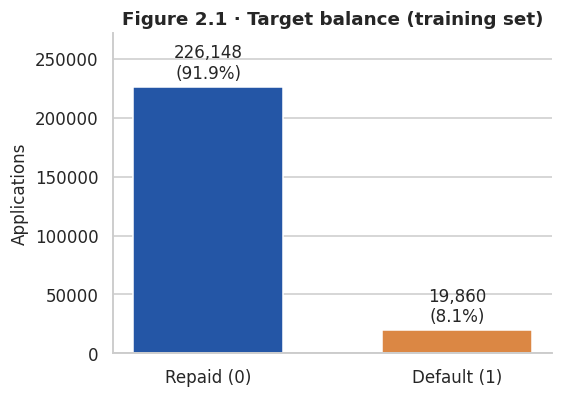

In [8]:
target_counts = train_df[TARGET].value_counts().sort_index()
target_share = 100 * target_counts / target_counts.sum()
overall_default_rate = target_share[1]

display(pd.DataFrame({
    "label": [TARGET_LABELS[value] for value in target_counts.index],
    "count": target_counts,
    "share (%)": target_share.round(2),
}).rename_axis(TARGET))

print(f"Accuracy of always predicting the majority class: {target_share.max():.2f}% (ROC-AUC of a constant score: 0.5)")
print(f"Imbalance ratio: {target_counts[0] / target_counts[1]:.1f} repaid applications per default")

# Figure 2.1: class balance
fig, ax = plt.subplots(figsize=(5, 3.5), layout="constrained")
bars = ax.bar(
    [TARGET_LABELS[value] for value in target_counts.index],
    target_counts.values, color=[BLUE, ORANGE], width=0.6,
)
ax.bar_label(bars, labels=[f"{count:,}\n({share:.1f}%)" for count, share in zip(target_counts, target_share)], padding=3)
ax.set(ylabel="Applications", ylim=(0, target_counts.max() * 1.2))
ax.grid(axis="x", visible=False)
ax.set_title("Figure 2.1 · Target balance (training set)")
plt.show()

Only 8.07% of applications default, about 11.4 repaid for each default. A model that never predicts default would score 91.93% accuracy while being useless, so accuracy says little here. We therefore use ROC-AUC as the primary metric, which is also how the competition is scored.

#### 2.3.2 Missing values

Most models cannot use missing values directly, so we first measure how much is missing by counting the features in each missingness band and plotting the most incomplete ones.

67 of 120 features have missing values.


,columns
missing (%),
"(0, 1]",10
"(1, 10]",0
"(10, 25]",7
"(25, 50]",9
"(50, 75]",41
"(75, 100]",0


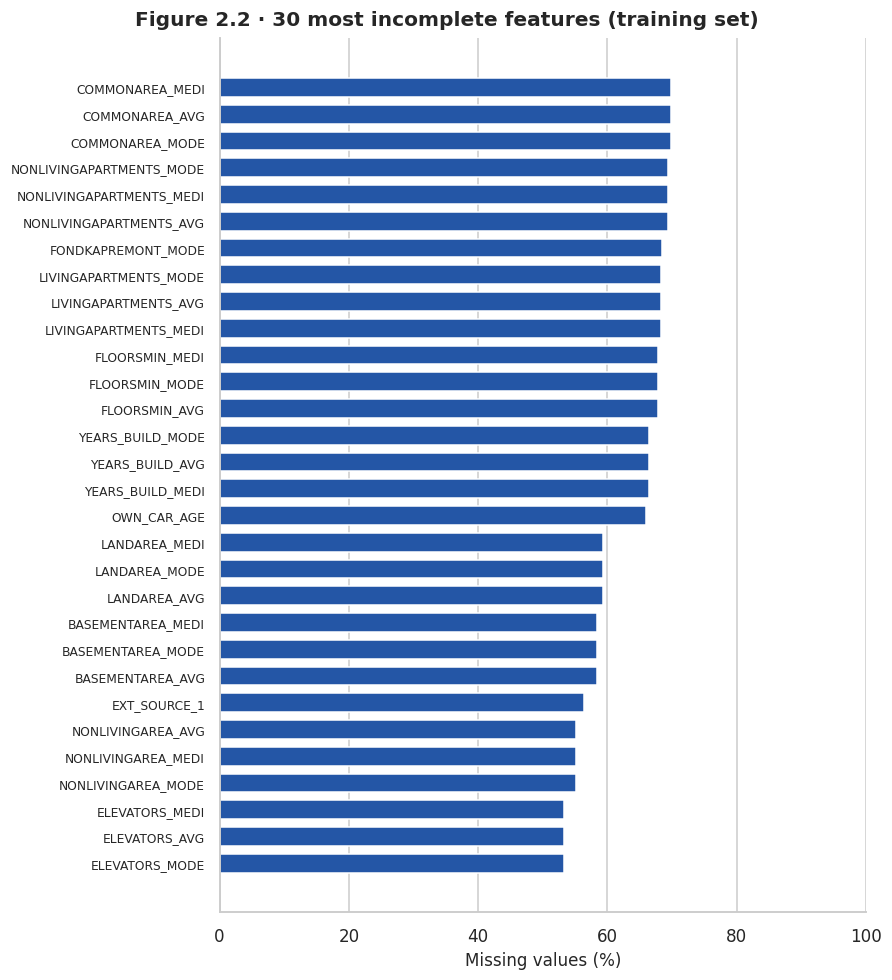

In [9]:
missing_pct = train_df[feature_cols].isna().mean().mul(100).sort_values(ascending=False)
columns_with_missing = missing_pct[missing_pct > 0]

missing_bands = pd.cut(columns_with_missing, bins=MISSING_BANDS).value_counts().sort_index()
print(f"{len(columns_with_missing)} of {len(feature_cols)} features have missing values.")
display(missing_bands.rename_axis("missing (%)").to_frame("columns"))

# Figure 2.2: the most incomplete features
top_missing = columns_with_missing.head(TOP_N_MISSING).sort_values()
fig, ax = plt.subplots(figsize=(8, 0.26 * len(top_missing) + 1), layout="constrained")
ax.barh(top_missing.index, top_missing.values, color=BLUE, height=0.7)
ax.set(xlabel="Missing values (%)", xlim=(0, 100), ylabel="")
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="y", visible=False)
fig.suptitle(f"Figure 2.2 · {len(top_missing)} most incomplete features (training set)", fontweight="bold")
plt.show()

67 of the 120 features have missing values, and 41 of them are 50–75% missing. Most of the features in Figure 2.2 are `_AVG`, `_MEDI` and `_MODE` housing features, which come in groups with near-identical missingness. Dropping them all would lose a lot of data, so imputation needs consideration.

Whether a value is missing can itself be informative, so we compare the default rate between applications where each feature is missing and where it is present. If the rates differ, it would support adding missing indicators during imputation (`SimpleImputer(add_indicator=True)`). Features where either group has fewer than 500 rows are skipped.

In [10]:
rows = []
for col in missing_pct[missing_pct > 0].index:
    is_missing = train_df[col].isna()
    # Skip features where either group is too small for a reliable rate
    if min(is_missing.sum(), (~is_missing).sum()) < MIN_GROUP_SIZE:
        continue
    rate_missing = 100 * train_df.loc[is_missing, TARGET].mean()
    rate_present = 100 * train_df.loc[~is_missing, TARGET].mean()
    rows.append({
        "column": col,
        "missing (%)": missing_pct[col],
        "default rate if missing (%)": rate_missing,
        "default rate if present (%)": rate_present,
        "gap (pct points)": rate_missing - rate_present,
    })

missing_vs_target = (
    pd.DataFrame(rows).set_index("column").sort_values("gap (pct points)", key=np.abs, ascending=False)
)
print(f"Table 2.3 · Default rate by missingness, top {TOP_N_TARGET_GAP} of {len(missing_vs_target)} columns by |gap| "
      f"(overall default rate: {overall_default_rate:.2f}%)")
display(missing_vs_target.head(TOP_N_TARGET_GAP).round(2))

Table 2.3 · Default rate by missingness, top 20 of 63 columns by |gap| (overall default rate: 8.07%)


,missing (%),default rate if missing (%),default rate if present (%),gap (pct points)
column,,,,
DEF_30_CNT_SOCIAL_CIRCLE,0.33,3.95,8.09,-4.14
OBS_60_CNT_SOCIAL_CIRCLE,0.33,3.95,8.09,-4.14
DEF_60_CNT_SOCIAL_CIRCLE,0.33,3.95,8.09,-4.14
OBS_30_CNT_SOCIAL_CIRCLE,0.33,3.95,8.09,-4.14
AMT_REQ_CREDIT_BUREAU_DAY,13.51,10.34,7.72,2.62
AMT_REQ_CREDIT_BUREAU_HOUR,13.51,10.34,7.72,2.62
AMT_REQ_CREDIT_BUREAU_WEEK,13.51,10.34,7.72,2.62
AMT_REQ_CREDIT_BUREAU_YEAR,13.51,10.34,7.72,2.62
AMT_REQ_CREDIT_BUREAU_MON,13.51,10.34,7.72,2.62


Missingness is related to default. Applications missing the credit bureau enquiry counts default at 10.34% vs 7.72%, and those missing housing features at about 9.2% vs 7.0%. This supports adding missing indicators. These gaps are associations only and do not explain why the values are missing.

#### 2.3.3 Statistical summaries

We summarise the numeric features with their ranges and skewness, because strongly skewed features with very different scales can hurt models such as logistic regression and SVMs. Binary flags are left out here because their distribution is covered by the near-constant check below.

In [11]:
n_unique = train_df[numeric_cols].nunique()
# Binary flags are covered by the near-constant check instead
continuous_cols = n_unique[n_unique > 2].index.tolist()

numeric_summary = train_df[continuous_cols].describe().T
numeric_summary["skew"] = train_df[continuous_cols].skew()
numeric_summary = numeric_summary.sort_values("skew", key=np.abs, ascending=False)
print("Table 2.4 · Continuous and count features, sorted by |skew|")
display(numeric_summary.round(3))

Table 2.4 · Continuous and count features, sorted by |skew|


,count,mean,std,min,25%,50%,75%,max,skew
AMT_INCOME_TOTAL,246008.0,168853.181,258960.632,25650.000,112500.000,147600.000,202500.000,1.1700e+08,375.128
AMT_REQ_CREDIT_BUREAU_DAY,212764.0,0.007,0.111,0.000,0.000,0.000,0.000,9.0000e+00,28.256
NONLIVINGAPARTMENTS_MODE,75279.0,0.008,0.046,0.000,0.000,0.000,0.004,1.0000e+00,16.175
NONLIVINGAPARTMENTS_MEDI,75279.0,0.009,0.048,0.000,0.000,0.000,0.004,1.0000e+00,15.634
NONLIVINGAPARTMENTS_AVG,75279.0,0.009,0.048,0.000,0.000,0.000,0.004,1.0000e+00,15.481
YEARS_BEGINEXPLUATATION_MEDI,126059.0,0.978,0.061,0.000,0.977,0.982,0.987,1.0000e+00,-15.353
YEARS_BEGINEXPLUATATION_AVG,126059.0,0.978,0.060,0.000,0.977,0.982,0.987,1.0000e+00,-15.314
AMT_REQ_CREDIT_BUREAU_HOUR,212764.0,0.006,0.083,0.000,0.000,0.000,0.000,4.0000e+00,14.601
YEARS_BEGINEXPLUATATION_MODE,126059.0,0.977,0.065,0.000,0.977,0.982,0.987,1.0000e+00,-14.594
OBS_30_CNT_SOCIAL_CIRCLE,245197.0,1.422,2.419,0.000,0.000,0.000,2.000,3.4800e+02,14.254


For categorical features, we look at how many categories each one has, because that decides how many columns one-hot encoding will create.

In [12]:
categorical_summary = pd.DataFrame({
    "unique": train_df[categorical_cols].nunique(),
    "missing (%)": train_df[categorical_cols].isna().mean() * 100,
    "most common": train_df[categorical_cols].mode().iloc[0],
    "most common share (%)": [
        100 * train_df[col].value_counts(normalize=True).iloc[0] for col in categorical_cols
    ],
}).sort_values("unique", ascending=False)
print("Table 2.5 · Categorical features, sorted by cardinality")
display(categorical_summary.round(2))

Table 2.5 · Categorical features, sorted by cardinality


,unique,missing (%),most common,most common share (%)
ORGANIZATION_TYPE,58,0.00,Business Entity Type 3,22.13
OCCUPATION_TYPE,18,31.28,Laborers,26.18
NAME_INCOME_TYPE,8,0.00,Working,51.64
NAME_TYPE_SUITE,7,0.42,Unaccompanied,81.15
WALLSMATERIAL_MODE,7,50.80,Panel,43.67
WEEKDAY_APPR_PROCESS_START,7,0.00,TUESDAY,17.55
NAME_FAMILY_STATUS,6,0.00,Married,63.88
NAME_HOUSING_TYPE,6,0.00,House / apartment,88.77
NAME_EDUCATION_TYPE,5,0.00,Secondary / secondary special,71.04
FONDKAPREMONT_MODE,4,68.38,reg oper account,75.90


We also look for near-constant features, where one value covers at least 99% of observed rows. These carry little information and are candidates for removal, although their rare values should be checked first.

In [13]:
# Share of the most common value among observed rows
top_share = pd.Series({
    col: train_df[col].value_counts(normalize=True).iloc[0] for col in feature_cols
})
near_constant = top_share[top_share >= NEAR_CONSTANT_SHARE].sort_values(ascending=False)
print(f"Table 2.6 · {len(near_constant)} features where one value covers at least {NEAR_CONSTANT_SHARE:.0%} of observed rows")
display((100 * near_constant).round(3).to_frame("top value share (%)"))

Table 2.6 · 19 features where one value covers at least 99% of observed rows


,top value share (%)
FLAG_MOBIL,100.000
FLAG_DOCUMENT_12,100.000
FLAG_DOCUMENT_10,99.998
FLAG_DOCUMENT_2,99.996
FLAG_DOCUMENT_4,99.991
FLAG_DOCUMENT_7,99.981
FLAG_DOCUMENT_17,99.975
FLAG_DOCUMENT_21,99.968
FLAG_DOCUMENT_20,99.950
FLAG_DOCUMENT_19,99.939


`AMT_INCOME_TOTAL` is the most skewed feature, so it likely needs a transform or a robust scaler. `ORGANIZATION_TYPE` has the most categories (58), which would add many columns when one-hot encoded. 19 features are near-constant, mostly `FLAG_DOCUMENT_*`.

#### 2.3.4 Anomalies

Some values are present but may not be real measurements, and treating them as real could distort a model. We run three checks.

**Impossible dates.** `DAYS_*` columns count backwards from the application date, so they should not be positive. We check each one and compare the default rate of any positive rows with the rest.

In [14]:
days_cols = [c for c in feature_cols if c.startswith("DAYS_")]
rows = []
for col in days_cols:
    is_positive = train_df[col] > 0
    rows.append({
        "column": col,
        "min (years)": train_df[col].min() / DAYS_PER_YEAR,
        "max (years)": train_df[col].max() / DAYS_PER_YEAR,
        "n positive": int(is_positive.sum()),
        "positive (%)": 100 * is_positive.mean(),
        "most common positive": train_df.loc[is_positive, col].mode().iloc[0] if is_positive.any() else np.nan,
        "default rate: positive (%)": 100 * train_df.loc[is_positive, TARGET].mean() if is_positive.any() else np.nan,
        "default rate: other (%)": 100 * train_df.loc[~is_positive, TARGET].mean(),
    })
print("Table 2.7 · DAYS_* range checks")
display(pd.DataFrame(rows).set_index("column"))

Table 2.7 · DAYS_* range checks


,min (years),max (years),n positive,positive (%),most common positive,default rate: positive (%),default rate: other (%)
column,,,,,,,
DAYS_BIRTH,-69.0732,-20.5038,0,0.0000,NaN,NaN,8.0729
DAYS_EMPLOYED,-49.0404,999.9808,44143,17.9437,365243.0,5.3689,8.6642
DAYS_REGISTRATION,-67.5483,0.0000,0,0.0000,NaN,NaN,8.0729
DAYS_ID_PUBLISH,-19.7043,0.0000,0,0.0000,NaN,NaN,8.0729
DAYS_LAST_PHONE_CHANGE,-11.7509,0.0000,0,0.0000,NaN,NaN,8.0729


`DAYS_EMPLOYED` is the only column with positive values. They are all the same value, 365243 days, or about 1,000 years, so it must be a placeholder. To understand what it stands for, we look at who these applicants are and compare the distribution with and without the placeholder.

Rows with the placeholder that also have ORGANIZATION_TYPE = XNA: 44,143 of 44,143
Table 2.8 · Income type of applicants with the placeholder


,applications
NAME_INCOME_TYPE,
Pensioner,44126
Unemployed,17


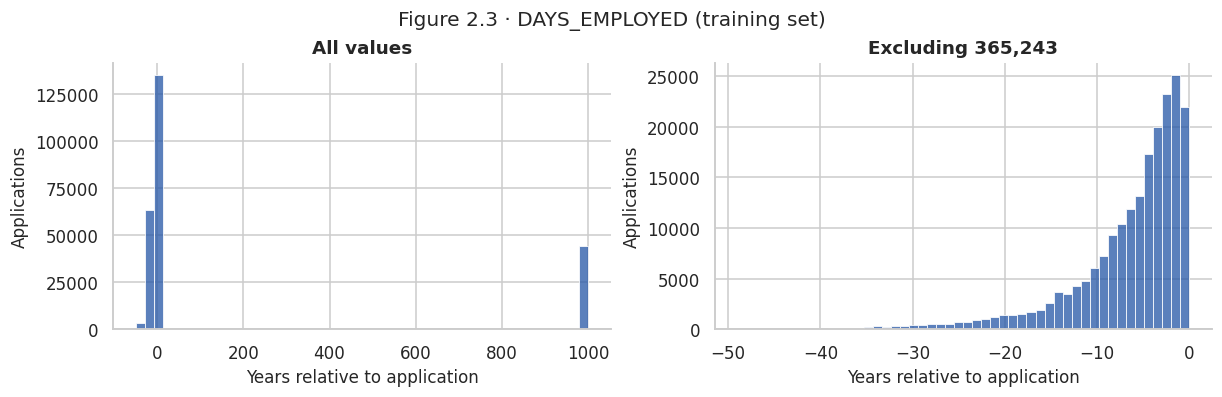

In [15]:
days_employed = train_df[EMPLOYMENT_COL]
# The most common positive value is the placeholder
employed_sentinel = days_employed[days_employed > 0].mode().iloc[0]
is_sentinel = days_employed == employed_sentinel

print(f"Rows with the placeholder that also have ORGANIZATION_TYPE = XNA: "
      f"{(train_df.loc[is_sentinel, 'ORGANIZATION_TYPE'] == 'XNA').sum():,} of {is_sentinel.sum():,}")
print("Table 2.8 · Income type of applicants with the placeholder")
display(train_df.loc[is_sentinel, "NAME_INCOME_TYPE"].value_counts().to_frame("applications"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
sns.histplot(days_employed / DAYS_PER_YEAR, bins=HIST_BINS, color=BLUE, ax=axes[0])
axes[0].set(title="All values", xlabel="Years relative to application", ylabel="Applications")
sns.histplot(days_employed[~is_sentinel] / DAYS_PER_YEAR, bins=HIST_BINS, color=BLUE, ax=axes[1])
axes[1].set(title=f"Excluding {employed_sentinel:,}", xlabel="Years relative to application", ylabel="Applications")
fig.suptitle(f"Figure 2.3 · {EMPLOYMENT_COL} (training set)")
plt.show()

The placeholder affects 44,143 rows (17.9%). Nearly all of these applicants are pensioners, and they are exactly the rows with `ORGANIZATION_TYPE = XNA`, so the value most likely means "not employed". They default less often (5.37% vs 8.66%). In preprocessing we should therefore replace the value with `NaN` and add a flag, so the signal is kept without the distortion shown in Figure 2.3.

**Placeholder categories.** Next we check for text values that really mean "missing" or "not applicable", since an imputer would not treat them as missing.

In [16]:
rows = []
for col in categorical_cols:
    for token in PLACEHOLDER_TOKENS:
        is_token = train_df[col] == token
        if is_token.any():
            rows.append({
                "column": col,
                "placeholder": token,
                "count": int(is_token.sum()),
                "share (%)": 100 * is_token.mean(),
                "default rate (%)": 100 * train_df.loc[is_token, TARGET].mean(),
            })
print(f"Table 2.9 · Placeholder categories (overall default rate: {overall_default_rate:.2f}%)")
display(pd.DataFrame(rows))

Table 2.9 · Placeholder categories (overall default rate: 8.07%)


,column,placeholder,count,share (%),default rate (%)
0,CODE_GENDER,XNA,2,0.0008,0.0000
1,NAME_FAMILY_STATUS,Unknown,2,0.0008,0.0000
2,ORGANIZATION_TYPE,XNA,44143,17.9437,5.3689


Apart from `ORGANIZATION_TYPE = XNA`, which matches the employment placeholder, placeholders are almost absent: `CODE_GENDER = XNA` and `NAME_FAMILY_STATUS = Unknown` each appear in only 2 rows. Their handling will have little effect on the models.

**Extreme values.** Finally, we compare the maximum of each amount and count column with its 99th percentile. A large ratio means a few very large values, which can dominate scaling and distance-based models.

In [17]:
tail_cols = [c for c in numeric_cols if c.startswith(("AMT_", "CNT_"))]
tails = train_df[tail_cols].quantile([0.5, 0.99, 1.0]).T
tails.columns = ["median", "p99", "max"]
# p99 can be 0 for rare counts, so avoid dividing by it
tails["max / p99"] = tails["max"] / tails["p99"].replace(0, np.nan)
print("Table 2.10 · Upper tails of AMT_* and CNT_* columns")
display(tails.sort_values("max / p99", ascending=False).round(2))

Table 2.10 · Upper tails of AMT_* and CNT_* columns


,median,p99,max,max / p99
AMT_INCOME_TOTAL,147600.0,472500.0,1.1700e+08,247.62
AMT_REQ_CREDIT_BUREAU_QRT,0.0,2.0,1.9000e+01,9.50
AMT_REQ_CREDIT_BUREAU_WEEK,0.0,1.0,8.0000e+00,8.00
AMT_REQ_CREDIT_BUREAU_MON,0.0,4.0,2.7000e+01,6.75
CNT_CHILDREN,0.0,3.0,1.9000e+01,6.33
CNT_FAM_MEMBERS,2.0,5.0,2.0000e+01,4.00
AMT_ANNUITY,24903.0,70033.5,2.5803e+05,3.68
AMT_REQ_CREDIT_BUREAU_YEAR,1.0,8.0,2.5000e+01,3.12
AMT_GOODS_PRICE,450000.0,1800000.0,4.0500e+06,2.25
AMT_CREDIT,514777.5,1862802.0,4.0500e+06,2.17


`AMT_INCOME_TOTAL` stands out, with a maximum of 117 million against a 99th percentile of 472,500, a ratio of about 248. This supports using a log transform or `RobustScaler` on income.

#### 2.3.5 Distributions

So far we have looked at summary numbers. We now plot the distributions of a few features by target, because a feature is only useful if its distribution differs between applicants who default and those who repay. We chose the three external scores, age, income and credit amount. Each class is normalised separately so that the much smaller default class stays visible. Income and credit are clipped at their 99th percentile so that the extreme values found above do not hide the shape.

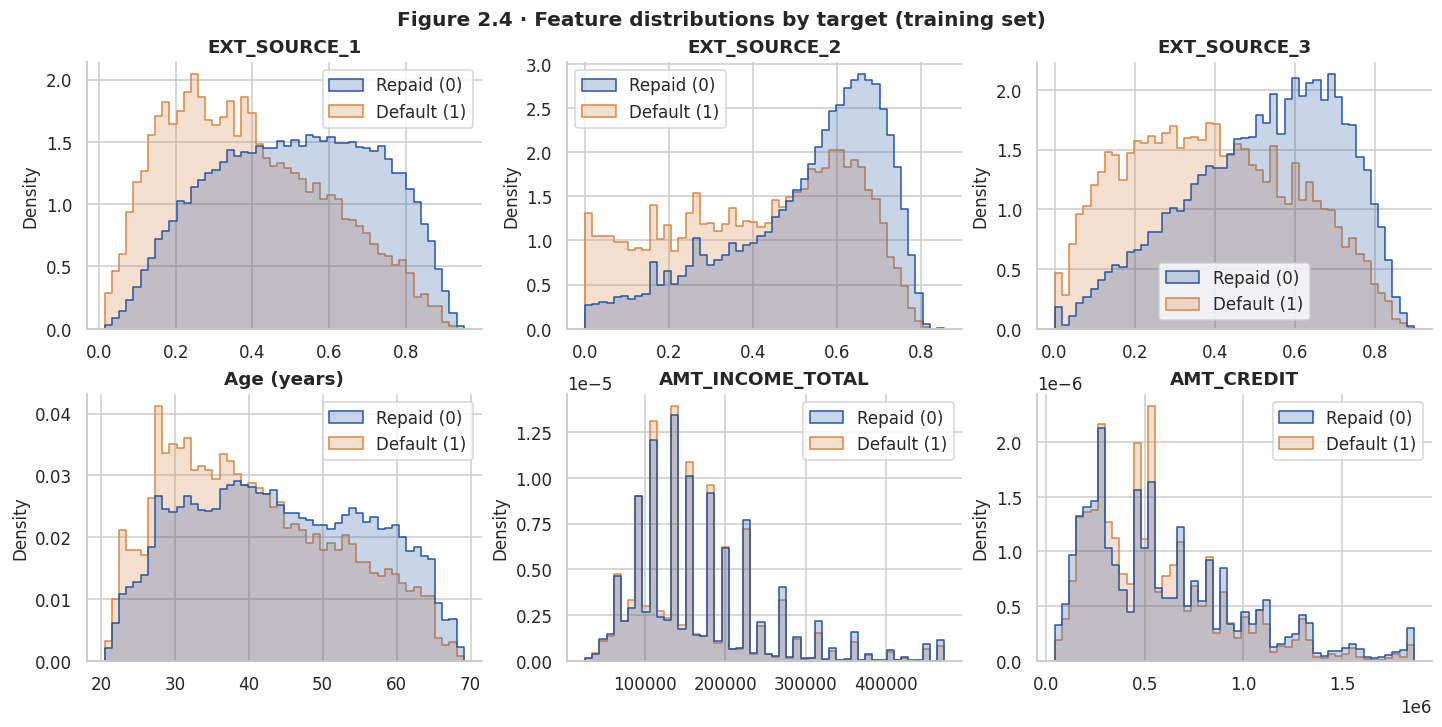

In [18]:
TAIL_CLIP_QUANTILE = 0.99

# Convert age to years and clip the heavy-tailed amounts, for plotting only
distribution_data = {
    "EXT_SOURCE_1": train_df["EXT_SOURCE_1"],
    "EXT_SOURCE_2": train_df["EXT_SOURCE_2"],
    "EXT_SOURCE_3": train_df["EXT_SOURCE_3"],
    "Age (years)": -train_df["DAYS_BIRTH"] / DAYS_PER_YEAR,
    "AMT_INCOME_TOTAL": train_df["AMT_INCOME_TOTAL"].clip(upper=train_df["AMT_INCOME_TOTAL"].quantile(TAIL_CLIP_QUANTILE)),
    "AMT_CREDIT": train_df["AMT_CREDIT"].clip(upper=train_df["AMT_CREDIT"].quantile(TAIL_CLIP_QUANTILE)),
}
target_names = train_df[TARGET].map(TARGET_LABELS)

# Figure 2.4: one panel per feature, with each class normalised separately
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), layout="constrained")
for ax, (name, values) in zip(axes.flat, distribution_data.items()):
    sns.histplot(
        x=values, hue=target_names, hue_order=list(TARGET_LABELS.values()), palette=[BLUE, ORANGE],
        bins=HIST_BINS, stat="density", common_norm=False, element="step", ax=ax,
    )
    ax.set(title=name, xlabel="", ylabel="Density")
    ax.get_legend().set_title("")
fig.suptitle("Figure 2.4 · Feature distributions by target (training set)", fontweight="bold")
plt.show()

The external scores separate the classes best: applicants who default tend to have lower scores on all three. Younger applicants also default more often. Income and credit amount have nearly the same distribution in both classes, so they are unlikely to be strong on their own. Both show sharp spikes, which suggests that values are often rounded.

### 2.4 Joining the auxiliary tables

We want to combine the auxiliary tables with the main table. They have many rows per applicant, so a direct join would duplicate applications. Instead, we summarise each table to a single row per applicant and then join the results.

The right summary depends on what a column measures:

| Aggregation | Used for | Example |
|:--|:--|:--|
| Sum | Separate things that really add up | Active debt across loans |
| Latest | Current state | Whether the latest application was refused |
| Mean or share | Typical behaviour, regardless of history length | Share of instalments paid late |
| Max | The worst case | Most days past due |
| Count | How much history exists | Number of prior loans |

Monthly balances are never summed, because the same balance repeats every month and would be counted many times. We also keep the feature set small, about 25 features, because logistic regression and SVMs work better with a small number of meaningful features.

`bureau_balance` is left out because of the coverage mismatch in Table 2.2.

These summaries use only each applicant's own records and never `TARGET`, so computing them for all applicants does not leak information between the parts. Imputers, scalers and feature selection will still be fitted on the training part only.

We start with two helpers. `aggregate` produces one row per applicant, and `ratio` avoids infinite values when a denominator is 0.

In [19]:
def aggregate(table, prefix, **features):
    """Summarise a table to one row per applicant; each keyword is feature_name=(column, statistic)."""
    return table.groupby(ID_COL).agg(**features).add_prefix(f"{prefix}_")


def ratio(numerator, denominator):
    """Divide two columns, returning NaN instead of infinity where the denominator is 0."""
    return numerator / denominator.replace(0, np.nan)

**`bureau`.** Each row is a separate loan, so amounts can be summed. We only sum active loans, because closed loans no longer represent debt the applicant owes. The debt-to-credit ratio shows how much of their active credit is used, which a raw debt total would not show. Sums skip missing values, and negative debts are kept because they may be real credit balances. The bureau date columns with impossible values are not used.

In [20]:
bureau = aux["bureau"]
# Only active loans represent debt the applicant still owes
is_active = bureau["CREDIT_ACTIVE"] == "Active"
bureau = bureau.assign(
    IS_ACTIVE=is_active,
    ACTIVE_DEBT=bureau["AMT_CREDIT_SUM_DEBT"].where(is_active),
    ACTIVE_CREDIT=bureau["AMT_CREDIT_SUM"].where(is_active),
)
bureau_features = aggregate(
    bureau, "BUREAU",
    LOAN_COUNT=("SK_ID_BUREAU", "count"),
    ACTIVE_SHARE=("IS_ACTIVE", "mean"),
    ACTIVE_DEBT=("ACTIVE_DEBT", "sum"),
    ACTIVE_CREDIT=("ACTIVE_CREDIT", "sum"),
    DAYS_OVERDUE_MAX=("CREDIT_DAY_OVERDUE", "max"),
    DAYS_CREDIT_LATEST=("DAYS_CREDIT", "max"),
)
# ACTIVE_CREDIT is only needed for this ratio, so it is dropped afterwards
bureau_features["BUREAU_DEBT_TO_CREDIT"] = ratio(bureau_features["BUREAU_ACTIVE_DEBT"], bureau_features["BUREAU_ACTIVE_CREDIT"])
bureau_features = bureau_features.drop(columns="BUREAU_ACTIVE_CREDIT")

**`previous_application`.** Approved and refused shares describe how earlier applications went, and the outcome of the latest one is the most recent signal. We sort from oldest to newest so that "last" is the latest application. Many applicants have several applications with the same latest decision date, so `SK_ID_PREV` settles ties. This keeps the result reproducible, although it may not always pick the truly latest application. We use only `DAYS_DECISION` for dates, since the other date columns contain the 365243 placeholder.

In [21]:
# Sort oldest to newest so that "last" is the latest; SK_ID_PREV settles ties
previous = aux["previous_application"].sort_values(["DAYS_DECISION", "SK_ID_PREV"])
previous = previous.assign(
    IS_APPROVED=(previous["NAME_CONTRACT_STATUS"] == "Approved").astype(int),
    IS_REFUSED=(previous["NAME_CONTRACT_STATUS"] == "Refused").astype(int),
    CREDIT_TO_REQUESTED=ratio(previous["AMT_CREDIT"], previous["AMT_APPLICATION"]),
)
previous_features = aggregate(
    previous, "PREV",
    APPLICATION_COUNT=("SK_ID_PREV", "count"),
    APPROVED_SHARE=("IS_APPROVED", "mean"),
    REFUSED_SHARE=("IS_REFUSED", "mean"),
    LATEST_REFUSED=("IS_REFUSED", "last"),
    DAYS_DECISION_LATEST=("DAYS_DECISION", "max"),
    CREDIT_TO_REQUESTED_MEAN=("CREDIT_TO_REQUESTED", "mean"),
)

**`POS_CASH_balance`.** These are monthly rows, so we measure how often the applicant was late and how bad it got, rather than summing. We use `SK_DPD_DEF`, which ignores small debts according to the data dictionary, so trivial shortfalls are not counted as late.

In [22]:
# Sort oldest to newest so that "last" is the latest month
pos = aux["POS_CASH_balance"].sort_values(["MONTHS_BALANCE", "SK_ID_PREV"])
pos = pos.assign(
    IS_LATE=pos["SK_DPD_DEF"] > 0,
    IS_ACTIVE=(pos["NAME_CONTRACT_STATUS"] == "Active").astype(int),
)
pos_features = aggregate(
    pos, "POS",
    LATE_MONTH_SHARE=("IS_LATE", "mean"),
    DPD_MAX=("SK_DPD_DEF", "max"),
    LATEST_ACTIVE=("IS_ACTIVE", "last"),
)

**`installments_payments`.** One instalment can be paid in several parts, which appear as separate rows. Without combining them first, a split payment would look like an underpayment, so we first roll the rows up to one per instalment. A shortfall of up to 1 currency unit is treated as rounding, not underpayment. We then measure how often and how late the applicant paid, and how much of what was due they paid.

In [23]:
PAYMENT_TOLERANCE = 1.0

# Combine part payments into one row per instalment
instalments = aux["installments_payments"].groupby(
    [ID_COL, "SK_ID_PREV", "NUM_INSTALMENT_VERSION", "NUM_INSTALMENT_NUMBER"], as_index=False,
).agg(
    AMT_DUE=("AMT_INSTALMENT", "first"),
    AMT_PAID=("AMT_PAYMENT", "sum"),
    DAYS_DUE=("DAYS_INSTALMENT", "first"),
    DAYS_PAID=("DAYS_ENTRY_PAYMENT", "max"),
)
# Early payments count as 0 days late
days_late = (instalments["DAYS_PAID"] - instalments["DAYS_DUE"]).clip(lower=0)
instalments = instalments.assign(
    DAYS_LATE=days_late,
    IS_LATE=days_late > 0,
    IS_UNDERPAID=instalments["AMT_DUE"] - instalments["AMT_PAID"] > PAYMENT_TOLERANCE,
    PAID_TO_DUE=ratio(instalments["AMT_PAID"], instalments["AMT_DUE"]),
)
instalment_features = aggregate(
    instalments, "INST",
    LATE_SHARE=("IS_LATE", "mean"),
    DAYS_LATE_MEAN=("DAYS_LATE", "mean"),
    DAYS_LATE_MAX=("DAYS_LATE", "max"),
    UNDERPAID_SHARE=("IS_UNDERPAID", "mean"),
    PAID_TO_DUE_MEAN=("PAID_TO_DUE", "mean"),
)

**`credit_card_balance`.** Utilisation is the balance divided by the credit limit. It is more comparable between applicants than the raw balance, because the same balance means something different on a small limit than on a large one. We keep both the latest value, for the current state, and the mean, for typical behaviour.

In [24]:
# Sort oldest to newest so that "last" is the latest month
card = aux["credit_card_balance"].sort_values(["MONTHS_BALANCE", "SK_ID_PREV"])
card = card.assign(
    UTILISATION=ratio(card["AMT_BALANCE"], card["AMT_CREDIT_LIMIT_ACTUAL"]),
    IS_LATE=card["SK_DPD_DEF"] > 0,
)
card_features = aggregate(
    card, "CC",
    UTILISATION_LATEST=("UTILISATION", "last"),
    UTILISATION_MEAN=("UTILISATION", "mean"),
    DRAWINGS_MEAN=("AMT_DRAWINGS_CURRENT", "mean"),
    DPD_MAX=("SK_DPD_DEF", "max"),
    LATE_MONTH_SHARE=("IS_LATE", "mean"),
)

**Joining the features.** We left join each feature table on `SK_ID_CURR`, because an inner join would drop applicants without history, and Kaggle needs a prediction for every test applicant. The train, validation and test parts all receive the same features.

Applicants with no records get a count of 0, since that is a known value. Other features stay `NaN` for the imputers in preprocessing. Most applicants have no Home Credit card, so we add a single `HAS_HC_CREDIT_CARD` flag that lets a model tell real card values from imputed ones. It covers Home Credit cards only, because cards from other lenders would appear in `bureau`.

The raw tables are deleted afterwards to free memory for model training, so re-running this section requires re-running the cell that loads `aux`.

In [25]:
aux_feature_tables = [bureau_features, previous_features, pos_features, instalment_features, card_features]
COUNT_FEATURES = ["BUREAU_LOAN_COUNT", "PREV_APPLICATION_COUNT"]


def join_aux_features(applications):
    """Left join the auxiliary features, keeping exactly one row per application."""
    joined = applications
    for features in aux_feature_tables:
        joined = joined.merge(features, left_on=ID_COL, right_index=True, how="left", validate="one_to_one")

    # No records means a count of 0; other features stay NaN for the imputers
    joined[COUNT_FEATURES] = joined[COUNT_FEATURES].fillna(0)
    joined["HAS_HC_CREDIT_CARD"] = joined[ID_COL].isin(card_features.index).astype(int)

    assert len(joined) == len(applications), "The join must not add or remove applications"
    return joined


train_joined = join_aux_features(train_df)
val_joined = join_aux_features(val_df)
test_joined = join_aux_features(app_test)

new_feature_cols = train_joined.columns.difference(train_df.columns, sort=False).tolist()

# Free the raw tables and working copies for model training
del aux, bureau, previous, pos, instalments, card

print("Table 2.11 · Shape of each part after the join")
display(pd.DataFrame({
    "rows": [len(part) for part in (train_joined, val_joined, test_joined)],
    "columns before": [part.shape[1] for part in (train_df, val_df, app_test)],
    "columns after": [part.shape[1] for part in (train_joined, val_joined, test_joined)],
}, index=["train", "validation", "Kaggle test"]))

print("Table 2.12 · New features (training part)")
new_feature_summary = train_joined[new_feature_cols].describe().T[["min", "50%", "mean", "max"]]
new_feature_summary.insert(0, "missing (%)", 100 * train_joined[new_feature_cols].isna().mean())
display(new_feature_summary.round(3))

Table 2.11 · Shape of each part after the join


,rows,columns before,columns after
train,246008,122,148
validation,61503,122,148
Kaggle test,48744,121,147


Table 2.12 · New features (training part)


,missing (%),min,50%,mean,max
BUREAU_LOAN_COUNT,0.000,0.0000e+00,4.000,4.761,9.4000e+01
BUREAU_ACTIVE_SHARE,14.326,0.0000e+00,0.375,0.413,1.0000e+00
BUREAU_ACTIVE_DEBT,14.326,-6.9788e+06,163113.232,630272.033,3.3450e+08
BUREAU_DAYS_OVERDUE_MAX,14.326,0.0000e+00,0.000,4.750,2.7920e+03
BUREAU_DAYS_CREDIT_LATEST,14.326,-2.9220e+03,-300.000,-489.689,0.0000e+00
BUREAU_DEBT_TO_CREDIT,30.372,-3.0909e+02,0.583,0.527,3.8251e+02
PREV_APPLICATION_COUNT,0.000,0.0000e+00,3.000,4.599,6.8000e+01
PREV_APPROVED_SHARE,5.355,0.0000e+00,0.800,0.749,1.0000e+00
PREV_REFUSED_SHARE,5.355,0.0000e+00,0.000,0.111,1.0000e+00
PREV_LATEST_REFUSED,5.355,0.0000e+00,0.000,0.112,1.0000e+00


The join adds 26 features without changing the number of rows in any part. Three things need handling in preprocessing:

- **Missing values:** card features are about 72% missing and `BUREAU_DEBT_TO_CREDIT` about 30%, since applicants with no active credit have no ratio.
- **Extreme values:** `INST_PAID_TO_DUE_MEAN` reaches 9,189, `BUREAU_DEBT_TO_CREDIT` ranges from -309 to 383, and `BUREAU_ACTIVE_DEBT` goes as low as about -7 million. These could hurt logistic regression and the SVM.
- **Scale:** the new features range from shares between 0 and 1 to amounts in the millions, so they will need scaling.

### 2.5 Correlations

We now use the joined training data to check which features are related to default and whether the new features add signal. We use Spearman correlation because it works on ranks, so the extreme values found above have less influence than they would on Pearson correlation. Correlation describes association, not causation, and a low value does not rule out a nonlinear relationship.

Each correlation uses only the rows where the feature is present. A credit card feature, for example, describes card holders only, so the table also shows how much of each feature is missing.

Table 2.13 · 20 features most correlated with TARGET (Spearman, training set)


,spearman,missing (%),source
EXT_SOURCE_3,-0.1667,19.8388,application
EXT_SOURCE_1,-0.1513,56.3376,application
EXT_SOURCE_2,-0.1465,0.2158,application
CC_UTILISATION_LATEST,0.1436,71.9607,auxiliary
CC_UTILISATION_MEAN,0.1290,71.9607,auxiliary
CC_DRAWINGS_MEAN,0.1066,71.6745,auxiliary
DAYS_BIRTH,0.0796,0.0000,application
BUREAU_ACTIVE_SHARE,0.0776,14.3264,auxiliary
BUREAU_DEBT_TO_CREDIT,0.0758,30.3718,auxiliary
BUREAU_DAYS_CREDIT_LATEST,0.0754,14.3264,auxiliary


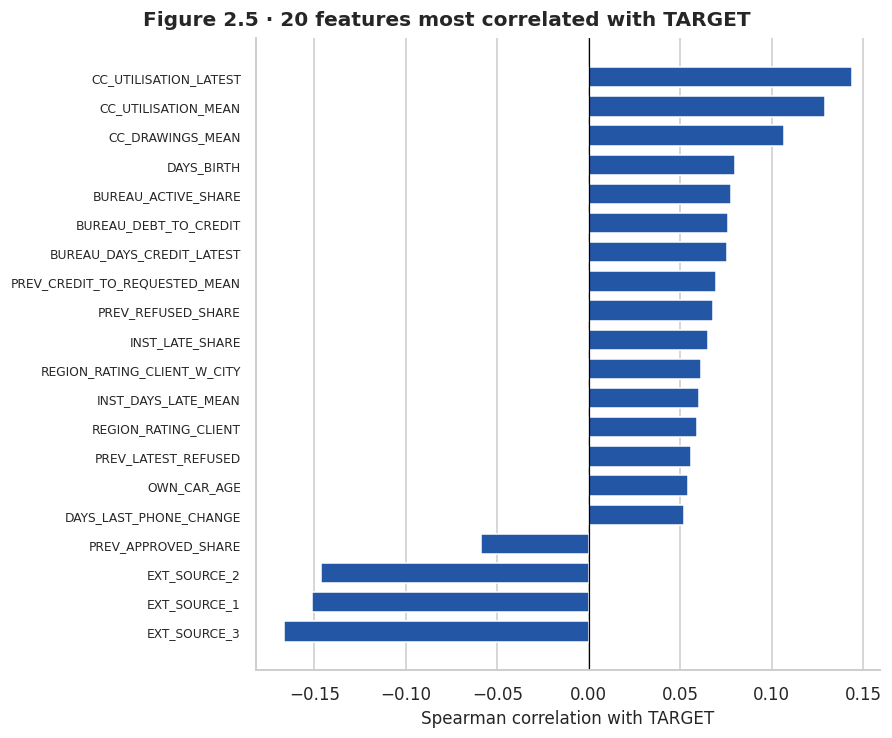

In [26]:
TOP_N_CORR = 20
TOP_N_HEATMAP = 12

# Constant features have no defined correlation
candidate_cols = [col for col in numeric_cols + new_feature_cols if train_joined[col].nunique() > 1]
target_corr = pd.Series({
    col: train_joined[col].corr(train_joined[TARGET], method="spearman") for col in candidate_cols
})
ranked_corr = target_corr.reindex(target_corr.abs().sort_values(ascending=False).index)
top_corr = ranked_corr.head(TOP_N_CORR)

print(f"Table 2.13 · {TOP_N_CORR} features most correlated with {TARGET} (Spearman, training set)")
display(pd.DataFrame({
    "spearman": top_corr,
    "missing (%)": 100 * train_joined[top_corr.index].isna().mean(),
    "source": ["auxiliary" if col in new_feature_cols else "application" for col in top_corr.index],
}).round(4))

# Figure 2.5: bars keep their sign, so risk-increasing and risk-reducing features are visible
plot_corr = top_corr.sort_values()
fig, ax = plt.subplots(figsize=(8, 0.28 * len(plot_corr) + 1), layout="constrained")
ax.barh(plot_corr.index, plot_corr.values, color=BLUE, height=0.7)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel=f"Spearman correlation with {TARGET}", ylabel="")
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="y", visible=False)
fig.suptitle(f"Figure 2.5 · {len(plot_corr)} features most correlated with {TARGET}", fontweight="bold")
plt.show()

The three external scores have the strongest correlations with default (-0.15 to -0.17), and they are negative, so higher scores go with fewer defaults. 12 of the top 20 features come from the auxiliary tables, so the join does add signal. The credit card features rank highly, but they are about 72% missing and describe card holders only, so they may not be as strong across all applicants. `DAYS_BIRTH` is positive because it counts backwards from the application date, which means younger applicants default more often, matching Figure 2.4.

Features that repeat each other add little and can make linear models unstable, so we also check the correlations among the strongest features. The matrix includes features only, not the target.

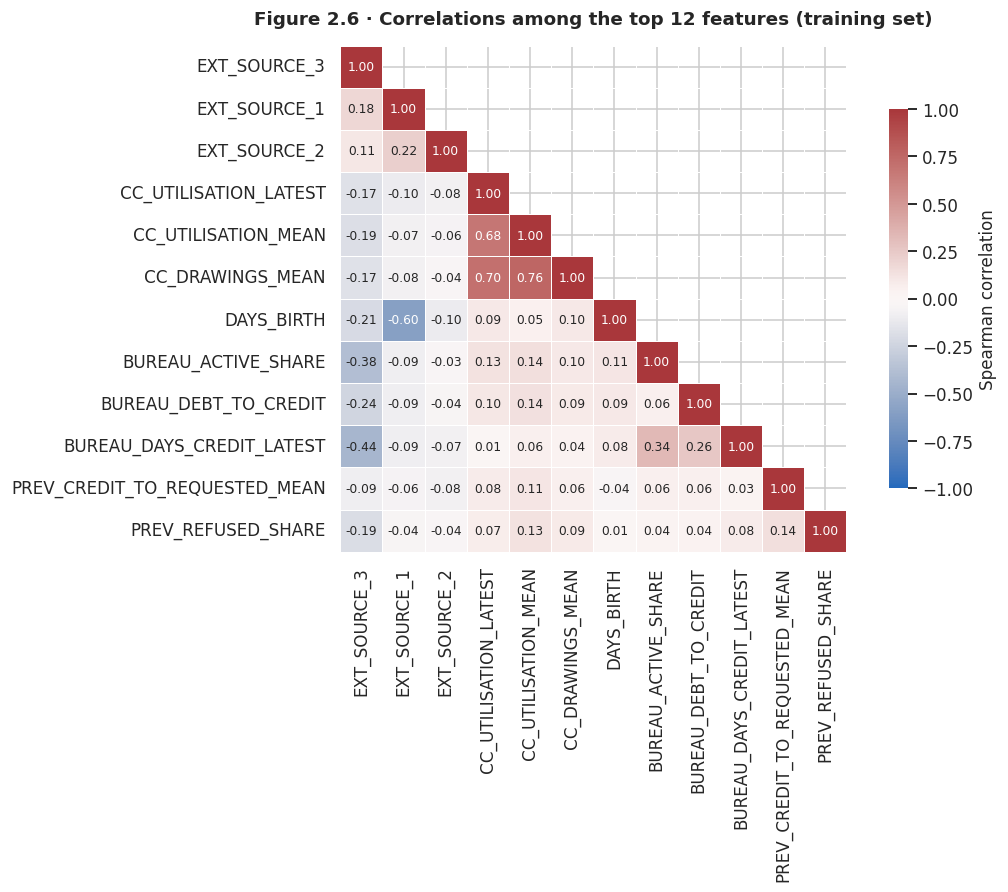

In [27]:
heatmap_cols = ranked_corr.head(TOP_N_HEATMAP).index.tolist()
feature_corr = train_joined[heatmap_cols].corr(method="spearman")

# Figure 2.6: the mask hides the repeated upper triangle
fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
sns.heatmap(
    feature_corr, mask=np.triu(np.ones_like(feature_corr, dtype=bool), k=1),
    vmin=-1, vmax=1, center=0, cmap="vlag", annot=True, fmt=".2f",
    annot_kws={"fontsize": 8}, square=True, linewidths=0.5, ax=ax,
    cbar_kws={"label": "Spearman correlation", "shrink": 0.75},
)
ax.set_title(f"Figure 2.6 · Correlations among the top {len(heatmap_cols)} features (training set)", pad=14)
plt.show()

The three external scores overlap little with each other (0.11 to 0.22), so each may add its own information. The credit card features overlap the most (up to 0.76), and `DAYS_BIRTH` is strongly related to `EXT_SOURCE_1` (-0.60). `SelectKBest` scores each feature on its own, so it will not remove this overlap by itself.

### 2.6 Initial hypotheses

The EDA leads to these hypotheses, which the modelling steps can test:

1. **External scores will be the most important inputs**, since they have the strongest relationship with default.
2. **Prior behaviour will improve on the application data alone**, since many of the top features come from the auxiliary tables, especially late payments, refusals and card utilisation.
3. **Missing values carry information**, since default rates differ between applicants with and without a value, so missing indicators should help.
4. **Linear models and SVMs will need careful scaling**, because of the skewed features and extreme values. The decision tree should be less sensitive to these.
5. **Validation accuracy will be misleading**, because always predicting "repaid" already scores about 92%, so ROC-AUC is the metric to compare.

## Step 3: Data Preprocessing & Cleaning

The auxiliary tables were already combined with the main table in 2.4, and the stratified 80/20 split was made before the EDA. This step prepares the joined data for the models. Every step that learns from the data is fitted on the training rows only and then applied unchanged to the validation and Kaggle test rows, which avoids data leakage.

### 3.1 Subsampling

The brief allows 100,000 training rows and 25,000 validation rows because of hardware limits, and the SVM is the slowest model to train. We use a stratified sample with the fixed seed, so the class balance is preserved and the sample is reproducible. Every model trains on these same rows, and the Kaggle test set is kept in full because it needs a prediction for every applicant.

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, VarianceThreshold, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, QuantileTransformer, RobustScaler, StandardScaler

TRAIN_ROWS = 100_000
VAL_ROWS = 25_000

# train_size draws a stratified sample of the requested size; the remainder is discarded
train_sample, _ = train_test_split(train_joined, train_size=TRAIN_ROWS, stratify=train_joined[TARGET], random_state=SEED)
val_sample, _ = train_test_split(val_joined, train_size=VAL_ROWS, stratify=val_joined[TARGET], random_state=SEED)

print("Table 3.1 · Rows used for modelling")
display(pd.DataFrame({
    "rows": [len(train_sample), len(val_sample), len(test_joined)],
    "default rate (%)": [100 * train_sample[TARGET].mean(), 100 * val_sample[TARGET].mean(), np.nan],
}, index=["train", "validation", "Kaggle test"]).round(3))

Table 3.1 · Rows used for modelling


,rows,default rate (%)
train,100000,8.073
validation,25000,8.072
Kaggle test,48744,NaN


### 3.2 Cleaning placeholder values

The EDA found values that stand for "missing" but would not be treated that way. We replace the `DAYS_EMPLOYED` placeholder (365243) and the placeholder categories in Table 2.9 with `NaN`, so that the imputers handle them. The signal is not lost, because the imputer adds a missing indicator for `DAYS_EMPLOYED`.

This step learns nothing from the data, so it can be applied to each part directly.

In [29]:
def clean_placeholders(table):
    """Replace known placeholder values with NaN."""
    cleaned = table.copy()
    cleaned[EMPLOYMENT_COL] = cleaned[EMPLOYMENT_COL].replace(employed_sentinel, np.nan)
    cleaned[categorical_cols] = cleaned[categorical_cols].replace(PLACEHOLDER_TOKENS, np.nan)
    return cleaned


X_train = clean_placeholders(train_sample).drop(columns=[ID_COL, TARGET])
X_val = clean_placeholders(val_sample).drop(columns=[ID_COL, TARGET])
X_test = clean_placeholders(test_joined).drop(columns=ID_COL)
y_train = train_sample[TARGET]
y_val = val_sample[TARGET]

### 3.3 Preprocessing pipeline

Following the course notebook [2], preprocessing is a scikit-learn `Pipeline`, so the same fitted steps are applied to every part. Each type of column gets its own treatment:

| Column type | Imputation | Then | Why |
|:--|:--|:--|:--|
| Continuous | Median, with a missing indicator | Scaling | The median is not affected by extreme values, and Table 2.3 showed that missingness is related to default |
| Credit card (`CC_*`) | Median, no indicator | Scaling | `HAS_HC_CREDIT_CARD` already says which applicants have no card records |
| Binary flags | Most frequent value | None | Scaling is not needed for values that are already 0 or 1 |
| Categorical | A separate `Missing` category | One-hot encoding | The categories have no natural order, and missing stays visible to the model. Categories not seen in training are ignored |

`VarianceThreshold` then removes constant columns, which carry no information and which `SelectKBest` cannot score. Finally, `SelectKBest` with `f_classif` keeps the `k` features whose means differ most between the two classes. It is used once, so all three models receive the same inputs and the comparison between them is fair.

In [30]:
all_features = X_train.columns
numeric_features = X_train.select_dtypes(include="number").columns
n_values = X_train[numeric_features].nunique()

# Group the columns by the treatment they need
binary_cols = n_values[n_values == 2].index.tolist()
card_cols = [col for col in numeric_features if col.startswith("CC_") and col not in binary_cols]
continuous_features = [col for col in numeric_features if col not in binary_cols + card_cols]
categorical_features = [col for col in all_features if col not in numeric_features]


def build_preprocessor(scaler, k):
    """Build the preprocessing pipeline with the given scaler and number of selected features."""
    columns = ColumnTransformer([
        ("continuous", Pipeline([
            ("impute", SimpleImputer(strategy="median", add_indicator=True)),
            ("scale", scaler),
        ]), continuous_features),
        ("card", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", scaler),
        ]), card_cols),
        ("binary", SimpleImputer(strategy="most_frequent"), binary_cols),
        ("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical_features),
    ])
    return Pipeline([
        ("columns", columns),
        ("variance", VarianceThreshold()),
        ("select", SelectKBest(score_func=f_classif, k=k)),
    ])


print("Table 3.2 · Column groups")
display(pd.DataFrame({"columns": [len(continuous_features), len(card_cols), len(binary_cols), len(categorical_features)]},
                     index=["continuous", "credit card", "binary", "categorical"]))

Table 3.2 · Column groups


,columns
continuous,91
credit card,5
binary,34
categorical,16


### 3.4 Choosing the scaler and the number of features

The EDA found skewed features and extreme values, so the choice of scaler could matter for logistic regression and the SVM. We compare three scalers: `StandardScaler` and `RobustScaler` from the course notebook, and `QuantileTransformer`, which maps each feature onto a normal distribution and so limits the effect of extreme values. We then compare several values of `k`.

Each option is scored by validation ROC-AUC with a default logistic regression, because it is fast and sensitive to scaling. The choice is made in two stages to keep the number of fits small. To favour a smaller and faster feature set for the SVM, we keep the smallest `k` within 0.001 of the best score.

In [31]:
KEEP_ALL = "all"
K_CANDIDATES = [25, 50, 100, 150, 200, 250, KEEP_ALL]
AUC_TOLERANCE = 0.001
LOGREG_MAX_ITER = 2000
QUANTILE_SUBSAMPLE = 10_000
scalers = {
    "StandardScaler": StandardScaler(),
    "RobustScaler": RobustScaler(),
    "QuantileTransformer": QuantileTransformer(output_distribution="normal", subsample=QUANTILE_SUBSAMPLE, random_state=SEED),
}


def validation_auc(scaler, k):
    """Fit the preprocessing and a default logistic regression on the training rows; return validation ROC-AUC."""
    preprocessor = build_preprocessor(scaler, k)
    train_ready = preprocessor.fit_transform(X_train, y_train)
    model = LogisticRegression(max_iter=LOGREG_MAX_ITER, random_state=SEED).fit(train_ready, y_train)
    return roc_auc_score(y_val, model.predict_proba(preprocessor.transform(X_val))[:, 1])


# Stage 1: compare scalers using all features
scaler_scores = pd.Series({name: validation_auc(scaler, KEEP_ALL) for name, scaler in scalers.items()})
best_scaler_name = scaler_scores.idxmax()
print("Table 3.3 · Validation ROC-AUC by scaler (all features)")
display(scaler_scores.round(4).to_frame("validation ROC-AUC"))

# Stage 2: compare k using the best scaler
k_scores = pd.Series({k: validation_auc(scalers[best_scaler_name], k) for k in K_CANDIDATES})
print(f"Table 3.4 · Validation ROC-AUC by k ({best_scaler_name})")
display(k_scores.round(4).to_frame("validation ROC-AUC").rename_axis("k"))

# Candidates are listed from smallest to largest, so the first one within tolerance is the smallest
best_k = k_scores.index[k_scores >= k_scores.max() - AUC_TOLERANCE][0]
print(f"Chosen: {best_scaler_name}, k = {best_k}")

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Table 3.3 · Validation ROC-AUC by scaler (all features)


,validation ROC-AUC
StandardScaler,0.7601
RobustScaler,0.7300
QuantileTransformer,0.7572


Table 3.4 · Validation ROC-AUC by k (StandardScaler)


,validation ROC-AUC
k,
25,0.7490
50,0.7500
100,0.7555
150,0.7600
200,0.7612
250,0.7610
all,0.7601


Chosen: StandardScaler, k = 200


`StandardScaler` scores highest (0.7601), slightly ahead of `QuantileTransformer` (0.7572). `RobustScaler` scores lowest (0.7300), but its logistic regression stopped at the iteration limit without converging, which is the warning shown above. Its score is therefore not a fair estimate of what it could reach. We keep `StandardScaler`, which converged quickly and scored best.

For the number of features, the score rises to 0.7612 at `k = 200` and then falls slightly to 0.7601 when all features are kept, so selection helps a little while removing 152 of the 352 columns. The lower scores at small `k` show that the many weak features together carry useful signal. No smaller `k` is within the 0.001 tolerance, so we use `k = 200`.

These choices were made on the validation set, as were the model settings tuned later, so validation scores may be slightly optimistic. The Kaggle scores give an independent check.

### 3.5 Final preprocessing

We fit the chosen pipeline on the training rows only and apply it to all three parts. The resulting arrays are the inputs for the three models. We also list the features with the highest selection scores, to check that the selection is sensible.

In [32]:
preprocessor = build_preprocessor(scalers[best_scaler_name], best_k)

# fit only on the training rows; validation and test are only transformed
X_train_ready = preprocessor.fit_transform(X_train, y_train)
X_val_ready = preprocessor.transform(X_val)
X_test_ready = preprocessor.transform(X_test)

selector = preprocessor.named_steps["select"]
candidate_names = preprocessor[:-1].get_feature_names_out()
selected_scores = pd.Series(selector.scores_, index=candidate_names)[selector.get_support()].sort_values(ascending=False)

print("Table 3.5 · Size of each part after preprocessing")
display(pd.DataFrame({
    "rows": [part.shape[0] for part in (X_train_ready, X_val_ready, X_test_ready)],
    "features": [part.shape[1] for part in (X_train_ready, X_val_ready, X_test_ready)],
    "missing values": [int(np.isnan(part).sum()) for part in (X_train_ready, X_val_ready, X_test_ready)],
}, index=["train", "validation", "Kaggle test"]))

print(f"Columns before selection: {len(candidate_names)}; selected: {X_train_ready.shape[1]}")
print("Table 3.6 · Selected features with the highest scores")
display(selected_scores.head(TOP_N_CORR).round(1).to_frame("f_classif score"))

Table 3.5 · Size of each part after preprocessing


,rows,features,missing values
train,100000,200,0
validation,25000,200,0
Kaggle test,48744,200,0


Columns before selection: 352; selected: 200
Table 3.6 · Selected features with the highest scores


,f_classif score
continuous__EXT_SOURCE_2,2547.3
continuous__EXT_SOURCE_3,2408.1
continuous__EXT_SOURCE_1,1088.3
continuous__DAYS_BIRTH,672.6
card__CC_UTILISATION_LATEST,629.6
card__CC_UTILISATION_MEAN,577.1
continuous__PREV_REFUSED_SHARE,567.4
continuous__BUREAU_ACTIVE_SHARE,490.4
continuous__DAYS_EMPLOYED,406.6
continuous__INST_LATE_SHARE,399.9


The final data has 200 features and no missing values in any part. The external scores, age and credit card utilisation have the highest scores, which matches the correlations in Table 2.13. Some selected features repeat each other, such as `CODE_GENDER_M` and `CODE_GENDER_F`, because `f_classif` scores each feature on its own.

In summary, preprocessing takes these steps, in order:

1. Replace placeholder values with `NaN`.
2. Impute missing values according to column type, adding missing indicators for continuous features.
3. Scale continuous and credit card features with `StandardScaler`.
4. One-hot encode categorical features.
5. Remove constant columns and keep the 200 best features with `SelectKBest`.

Steps 2 to 5 are fitted on the 100,000 training rows only. `X_train_ready`, `X_val_ready` and `X_test_ready` are the inputs for the models.

## Step 4: Model 1: Logistic Regression

We use a regularised logistic regression as the baseline. It takes the training, validation and test matrices from Step 3, so the three models are compared on the same applicants and features. `C` controls the inverse regularisation strength. Smaller values apply a stronger penalty to large coefficients.

### 4.1 Settings and helpers

The logistic regression and decision tree each produce a probability for class 1. We use the continuous probability for ROC-AUC. For classification metrics, each model selects its own cutoff on the validation rows. A cutoff of 0.50 is shown as a reference. The Kaggle files contain probabilities.


In [33]:
from time import perf_counter

from sklearn.base import clone
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import ParameterGrid
from threadpoolctl import threadpool_limits

CPU_THREADS = 2
PROBABILITY_THRESHOLD = 0.5
THRESHOLD_GRID = np.arange(1, 101) / 100
LOGREG_GRID = {"C": [0.001, 0.01, 0.1, 1.0, 10.0]}
LOGREG_SUBMISSION_PATH = Path("submission_logreg.csv")


def probability_metrics(y_true, probabilities, threshold):
    """Use the positive-class probabilities for AUC and threshold them for the other metrics."""
    predicted = (probabilities >= threshold).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "precision": precision_score(y_true, predicted, zero_division=0),
        "recall": recall_score(y_true, predicted, zero_division=0),
        "F1": f1_score(y_true, predicted, zero_division=0),
        "accuracy": accuracy_score(y_true, predicted),
    }


def tune_probability_model(estimator, param_grid):
    """Fit each candidate on the training rows and rank candidates by validation ROC-AUC."""
    configs = list(ParameterGrid(param_grid))
    records = []
    for config in configs:
        candidate = clone(estimator).set_params(**config)
        with threadpool_limits(limits=CPU_THREADS):
            start = perf_counter()
            candidate.fit(X_train_ready, y_train)
            fit_seconds = perf_counter() - start
            validation_probabilities = candidate.predict_proba(X_val_ready)[:, 1]
        records.append({
            **config,
            "ROC-AUC": roc_auc_score(y_val, validation_probabilities),
            "fit time (s)": fit_seconds,
        })

    ranked = pd.DataFrame(records).sort_values("ROC-AUC", ascending=False, kind="stable")
    return configs[ranked.index[0]], ranked.reset_index(drop=True)


def select_probability_threshold(y_true, probabilities, model_name):
    """Evaluate the validation operating points at each whole-percentage cutoff."""
    results = []
    for threshold in THRESHOLD_GRID:
        predicted = probabilities >= threshold
        tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
        results.append({
            "threshold": threshold,
            "predicted defaults": tp + fp,
            "true positives": tp,
            "false positives": fp,
            "false positive rate": fp / (tn + fp),
            "precision": tp / (tp + fp) if tp + fp else 0.0,
            "recall": tp / (tp + fn),
            "F1": 2 * tp / (2 * tp + fp + fn),
        })

    sweep = pd.DataFrame(results)
    # When F1 ties, use the higher cutoff, which flags the same number of applicants or fewer.
    selected = sweep.sort_values(["F1", "threshold"], ascending=[False, False]).iloc[0]
    baseline = sweep.loc[sweep["threshold"] == PROBABILITY_THRESHOLD].iloc[0]
    operating_points = pd.DataFrame([baseline, selected], index=["0.50 reference", "Maximum validation F1"])
    print(f"{model_name}: threshold comparison on validation rows")
    display(operating_points[[
        "threshold", "predicted defaults", "true positives", "false positives", "precision", "recall", "F1",
    ]].astype({"predicted defaults": int, "true positives": int, "false positives": int}).round(4))
    return float(selected["threshold"]), sweep


def show_probability_results(train_probabilities, validation_probabilities, threshold, section):
    """Report metrics and two confusion matrices for the best candidate."""
    metrics = pd.DataFrame({
        "train": probability_metrics(y_train, train_probabilities, threshold),
        "validation": probability_metrics(y_val, validation_probabilities, threshold),
    })
    print(f"Table {section}.2 · Best configuration, training and validation metrics")
    display(metrics.round(4))

    class_names = [TARGET_LABELS[0], TARGET_LABELS[1]]
    for part, y_true, probabilities in [
        ("training", y_train, train_probabilities),
        ("validation", y_val, validation_probabilities),
    ]:
        predicted = (probabilities >= threshold).astype(int)
        matrix = confusion_matrix(y_true, predicted, labels=[0, 1])
        print(f"Table {section}.3 · Confusion matrix, {part} (rows: actual, columns: predicted)")
        display(pd.DataFrame(matrix, index=class_names, columns=class_names))
        print(f"Predicted defaults at the {threshold:.2f} threshold: {predicted.sum():,}")
    return metrics


def write_probability_submission(probabilities, path, section):
    """Align each probability with its applicant ID and follow the sample submission order."""
    test_ids = pd.Index(test_joined[ID_COL], name=ID_COL)
    sample_ids = pd.Index(pd.read_csv(DATA_DIR / "sample_submission.csv")[ID_COL], name=ID_COL)
    assert test_ids.is_unique and sample_ids.is_unique, "Applicant IDs must be unique."
    order = test_ids.get_indexer(sample_ids)
    assert len(probabilities) == len(test_ids) == len(sample_ids), "Expected one probability per test applicant."
    assert (order >= 0).all(), "The test IDs must match the sample submission."
    assert np.isfinite(probabilities).all() and ((0 <= probabilities) & (probabilities <= 1)).all()

    submission = pd.DataFrame({ID_COL: sample_ids, TARGET: probabilities[order]})
    submission.to_csv(path, index=False, float_format="%.12g")
    print(f"Table {section}.4 · First rows of {path.name} ({len(submission):,} rows)")
    display(submission.head())


### 4.2 Hyperparameter tuning

We test five values of `C`. Each candidate is trained on the same rows and ranked by validation ROC-AUC. After selecting `C`, we use its validation probabilities to choose the classification cutoff.


In [34]:
logreg_base = LogisticRegression(solver="lbfgs", max_iter=LOGREG_MAX_ITER, random_state=SEED)
best_logreg_config, logreg_tuning = tune_probability_model(logreg_base, LOGREG_GRID)

print("Table 4.1 · Logistic regression validation results by C, best first")
display(logreg_tuning.round(4))
print(f"Best configuration: {best_logreg_config}")


Table 4.1 · Logistic regression validation results by C, best first


,C,ROC-AUC,fit time (s)
0,0.100,0.7613,4.8756
1,10.000,0.7613,8.1873
2,1.000,0.7612,5.6367
3,0.010,0.7609,7.8427
4,0.001,0.7584,2.4670


Best configuration: {'C': 0.1}


### 4.3 Best configuration and classification threshold

We fit the selected configuration on the training rows. On the validation rows, we test every whole-percentage cutoff from 0.01 to 1.00 and choose the one with the highest positive-class F1. Ties go to the higher cutoff. We show the result at 0.50 alongside the selected cutoff to make the change in precision, recall and the number of flagged defaults visible.

The same selected cutoff is applied to both the training and validation confusion matrices. The validation F1 at this cutoff is a tuning result.


In [35]:
best_logreg = clone(logreg_base).set_params(**best_logreg_config)
with threadpool_limits(limits=CPU_THREADS):
    start = perf_counter()
    best_logreg.fit(X_train_ready, y_train)
    logreg_fit_seconds = perf_counter() - start
    logreg_train_probabilities = best_logreg.predict_proba(X_train_ready)[:, 1]
    logreg_val_probabilities = best_logreg.predict_proba(X_val_ready)[:, 1]

logreg_threshold, logreg_threshold_sweep = select_probability_threshold(
    y_val, logreg_val_probabilities, "Logistic regression"
)
logreg_metrics = show_probability_results(
    logreg_train_probabilities, logreg_val_probabilities, logreg_threshold, section=4
)
print(f"Final fit time: {logreg_fit_seconds:.2f} s")


Logistic regression: threshold comparison on validation rows


,threshold,predicted defaults,true positives,false positives,precision,recall,F1
0.50 reference,0.50,91,49,42,0.5385,0.0243,0.0465
Maximum validation F1,0.13,4426,997,3429,0.2253,0.4941,0.3094


Table 4.2 · Best configuration, training and validation metrics


,train,validation
ROC-AUC,0.7651,0.7613
precision,0.2233,0.2253
recall,0.4970,0.4941
F1,0.3082,0.3094
accuracy,0.8199,0.8220


Table 4.3 · Confusion matrix, training (rows: actual, columns: predicted)


,Repaid (0),Default (1)
Repaid (0),77976,13951
Default (1),4061,4012


Predicted defaults at the 0.13 threshold: 17,963
Table 4.3 · Confusion matrix, validation (rows: actual, columns: predicted)


,Repaid (0),Default (1)
Repaid (0),19553,3429
Default (1),1021,997


Predicted defaults at the 0.13 threshold: 4,426
Final fit time: 4.97 s


### 4.4 Kaggle submission

The final logistic regression predicts a probability for each test applicant using the preprocessed test matrix. We pair each probability with the corresponding `SK_ID_CURR` before writing the file.


In [48]:
with threadpool_limits(limits=CPU_THREADS):
    logreg_test_probabilities = best_logreg.predict_proba(X_test_ready)[:, 1]
write_probability_submission(logreg_test_probabilities, LOGREG_SUBMISSION_PATH, section=4)


Table 4.4 · First rows of submission_logreg.csv (48,744 rows)


,SK_ID_CURR,TARGET
0,100001,0.0447
1,100005,0.1392
2,100013,0.0368
3,100028,0.0198
4,100038,0.1358


In [49]:
#from google.colab import files
#files.download("submission_logreg.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 4.5 Discussion

Validation AUC compares the ranking produced by each `C`. At the selected operating point, precision shows the share of flagged applicants who actually default, and recall shows the share of actual defaults the model flags. The logistic regression coefficients can also be examined on the preprocessed feature scale.


## Step 5: Model 2: Support Vector Machine (SVM)

We train a support vector classifier with cuML, which runs on an NVIDIA GPU. This section therefore needs a GPU runtime, such as Colab with a T4 GPU.

Three design choices follow from the data:

- **Class imbalance:** only about 8% of applicants default, so without weighting a large-margin classifier can predict "repaid" for nearly everyone. `class_weight="balanced"` raises the penalty for misclassifying a default in proportion to how rare defaults are.
- **Scores for tuning, probabilities for Kaggle:** ROC-AUC only needs a ranking, and the signed distance from `decision_function` provides one, so the candidates are tuned without probability estimates. Only the best configuration is refitted with `probability=True` for the Kaggle file, as described in 5.5.
- **Input type:** the arrays are converted to `float32`, which halves GPU memory use and is precise enough for standardised features.

### 5.1 Checking the GPU runtime

In [37]:
import importlib.util
import shutil
import subprocess
import sys

CUML_PACKAGE = "cuml-cu12"  # RAPIDS build for CUDA 12, used by Colab GPU runtimes

if shutil.which("nvidia-smi") is None:
    raise RuntimeError("cuML needs an NVIDIA GPU. In Colab, choose Runtime > Change runtime type > T4 GPU.")
print(subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True, check=True).stdout)

if importlib.util.find_spec("cuml") is None:
    print(f"Installing {CUML_PACKAGE}...")
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", CUML_PACKAGE], check=True)

GPU 0: Tesla T4 (UUID: GPU-8ba0affe-0e24-ca8a-c047-946529a6338d)



### 5.2 Settings and helpers

We tune three hyperparameters on the validation set: `kernel`, `C` and, for the RBF kernel, `gamma`. The RBF `gamma` values are multiples of `1 / n_features`, so they adapt to the number of selected features.

Hard labels come from the sign of the decision function, which is how cuML's own `predict` defines them. This means each part only has to be scored once per model.

In [38]:
import json
import time

from cuml.svm import SVC as CumlSVC
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score

SVM_CLASS_WEIGHT = "balanced"
SVM_TOL = 1e-3
SVM_CACHE_MB = 4096

# Hyperparameter grid
LINEAR_C_VALUES = [0.01, 0.1, 1]
RBF_C_VALUES = [0.1, 1]
RBF_GAMMA_FACTORS = [0.1, 1]  # multiples of 1 / n_features

# Inputs for cuML: float32 halves GPU memory use
X_train_svm = np.asarray(X_train_ready, dtype=np.float32)
X_val_svm = np.asarray(X_val_ready, dtype=np.float32)
X_test_svm = np.asarray(X_test_ready, dtype=np.float32)
y_train_svm = y_train.to_numpy()
y_val_svm = y_val.to_numpy()
n_rows, n_features = X_train_svm.shape

svm_configs = [{"kernel": "linear", "C": C} for C in LINEAR_C_VALUES] + [
    {"kernel": "rbf", "C": C, "gamma": factor / n_features}
    for C in RBF_C_VALUES for factor in RBF_GAMMA_FACTORS
]

SVM_RESULTS_PATH = Path(f"svm_tuning_{n_rows}x{n_features}.csv")
SVM_SUBMISSION_PATH = Path("submission_svm.csv")


def fit_svm(config):
    """Train one cuML SVC on the training rows with the given hyperparameters."""
    model = CumlSVC(class_weight=SVM_CLASS_WEIGHT, tol=SVM_TOL, cache_size=SVM_CACHE_MB, random_state=SEED, **config)
    return model.fit(X_train_svm, y_train_svm)


def decision_scores(model, X):
    """Return the signed distance from the margin as a one-dimensional NumPy array."""
    scores = model.decision_function(X)
    scores = scores.get() if type(scores).__module__.startswith("cupy") else scores
    return np.asarray(scores).ravel()


def classification_metrics(y_true, scores):
    """Compute the classification metrics; a score of 0 or more means default."""
    predicted = (scores >= 0).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y_true, scores),
        "precision": precision_score(y_true, predicted, zero_division=0),
        "recall": recall_score(y_true, predicted, zero_division=0),
        "F1": f1_score(y_true, predicted, zero_division=0),
        "accuracy": accuracy_score(y_true, predicted),
    }


print(f"Training on {n_rows:,} rows and {n_features} features; {len(svm_configs)} candidates.")

Training on 100,000 rows and 200 features; 7 candidates.


### 5.3 Hyperparameter tuning

Each candidate is trained on the training rows and scored on the validation rows. Candidates are ranked by validation ROC-AUC, the competition metric. Accuracy is reported, but it is not used to choose a model because of the class imbalance.

In [39]:
svm_records = pd.read_csv(SVM_RESULTS_PATH).to_dict("records") if SVM_RESULTS_PATH.exists() else []
finished = {record["config"] for record in svm_records}

for config in svm_configs:
    label = json.dumps(config, sort_keys=True)
    if label in finished:
        print(f"Already finished: {label}")
        continue

    start = time.perf_counter()
    model = fit_svm(config)
    fit_seconds = time.perf_counter() - start

    metrics = classification_metrics(y_val_svm, decision_scores(model, X_val_svm))
    svm_records.append({
        "config": label, "kernel": config["kernel"], "C": config["C"], "gamma": config.get("gamma", np.nan),
        **metrics, "support vectors": int(model.support_.shape[0]), "fit time (s)": fit_seconds,
    })
    pd.DataFrame(svm_records).to_csv(SVM_RESULTS_PATH, index=False)
    print(f"{label}: validation ROC-AUC {metrics['ROC-AUC']:.4f}, fitted in {fit_seconds:.0f} s")
    del model  # free GPU memory before the next candidate

current_labels = [json.dumps(config, sort_keys=True) for config in svm_configs]
svm_tuning = pd.DataFrame(svm_records).query("config in @current_labels").sort_values("ROC-AUC", ascending=False)
best_svm_config = json.loads(svm_tuning.iloc[0]["config"])

print("Table 5.1 · SVM validation results by hyperparameters, best first")
display(svm_tuning.drop(columns="config").reset_index(drop=True).round(4))
print(f"Best configuration: {best_svm_config}")

{"C": 0.01, "kernel": "linear"}: validation ROC-AUC 0.7615, fitted in 6 s
{"C": 0.1, "kernel": "linear"}: validation ROC-AUC 0.7614, fitted in 9 s
{"C": 1, "kernel": "linear"}: validation ROC-AUC 0.7613, fitted in 42 s
{"C": 0.1, "gamma": 0.0005, "kernel": "rbf"}: validation ROC-AUC 0.7564, fitted in 3 s
{"C": 0.1, "gamma": 0.005, "kernel": "rbf"}: validation ROC-AUC 0.7615, fitted in 4 s
{"C": 1, "gamma": 0.0005, "kernel": "rbf"}: validation ROC-AUC 0.7626, fitted in 4 s
{"C": 1, "gamma": 0.005, "kernel": "rbf"}: validation ROC-AUC 0.7586, fitted in 4 s
Table 5.1 · SVM validation results by hyperparameters, best first


,kernel,C,gamma,ROC-AUC,precision,recall,F1,accuracy,support vectors,fit time (s)
0,rbf,1.00,0.0005,0.7626,0.1719,0.7022,0.2762,0.7030,70114,3.6451
1,linear,0.01,NaN,0.7615,0.1698,0.7017,0.2734,0.6989,69115,6.0751
2,rbf,0.10,0.0050,0.7615,0.1703,0.6819,0.2725,0.7062,71902,3.5516
3,linear,0.10,NaN,0.7614,0.1699,0.7012,0.2736,0.6994,68849,8.7744
4,linear,1.00,NaN,0.7613,0.1696,0.7002,0.2731,0.6991,68792,41.6755
5,rbf,1.00,0.0050,0.7586,0.1757,0.6397,0.2757,0.7287,66437,4.1997
6,rbf,0.10,0.0005,0.7564,0.1678,0.6923,0.2702,0.6981,75090,3.4697


Best configuration: {'C': 1, 'gamma': 0.0005, 'kernel': 'rbf'}


### 5.4 Best configuration: training and validation metrics

We retrain the best configuration on the same training rows and report the metrics on both parts. The gap between them shows how much the model overfits.

In [40]:
import warnings

start = time.perf_counter()
# probability=True used for the Kaggle probabilities.
# cuML warns that this option will be removed in a later release; the installed version supports it.
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="The `probability` parameter", category=FutureWarning)
    best_svm = fit_svm({**best_svm_config, "probability": True})
best_svm_fit_seconds = time.perf_counter() - start

svm_train_scores = decision_scores(best_svm, X_train_svm)
svm_val_scores = decision_scores(best_svm, X_val_svm)

svm_metrics = pd.DataFrame({
    "train": classification_metrics(y_train_svm, svm_train_scores),
    "validation": classification_metrics(y_val_svm, svm_val_scores),
})
print("Table 5.2 · Best SVM: training and validation metrics")
display(svm_metrics.round(4))

class_names = list(TARGET_LABELS.values())
for part, y_true, scores in [("training", y_train_svm, svm_train_scores), ("validation", y_val_svm, svm_val_scores)]:
    print(f"Table 5.3 · Best SVM: confusion matrix, {part} (rows: actual, columns: predicted)")
    display(pd.DataFrame(confusion_matrix(y_true, (scores >= 0).astype(int)), index=class_names, columns=class_names))

print(f"Final fit time: {best_svm_fit_seconds:.0f} s; support vectors: {best_svm.support_.shape[0]:,}")

Table 5.2 · Best SVM: training and validation metrics


,train,validation
ROC-AUC,0.7716,0.7626
precision,0.1722,0.1719
recall,0.7026,0.7022
F1,0.2766,0.2762
accuracy,0.7033,0.7030


Table 5.3 · Best SVM: confusion matrix, training (rows: actual, columns: predicted)


,Repaid (0),Default (1)
Repaid (0),64657,27270
Default (1),2401,5672


Table 5.3 · Best SVM: confusion matrix, validation (rows: actual, columns: predicted)


,Repaid (0),Default (1)
Repaid (0),16158,6824
Default (1),601,1417


Final fit time: 19 s; support vectors: 70,114


### 5.5 Kaggle submission

We need a predicted probability, while an SVM produces an unbounded score. The best model is therefore fitted with `probability=True`, which makes cuML learn Platt scaling, a logistic mapping of the decision scores, using 5-fold cross-validation on the training rows. `predict_proba` applies this mapping. It only rescales the scores and keeps their order, so it does not change ROC-AUC.

The test rows have already passed through the preprocessing pipeline fitted on the training rows.

In [41]:
svm_test_probabilities = best_svm.predict_proba(X_test_svm)
# Depending on the cuML version, the result may be a CuPy array on the GPU
if type(svm_test_probabilities).__module__.startswith("cupy"):
    svm_test_probabilities = svm_test_probabilities.get()
svm_test_probabilities = np.asarray(svm_test_probabilities)[:, 1]  # column 1 is the default class

svm_submission = pd.DataFrame({ID_COL: test_joined[ID_COL].to_numpy(), TARGET: svm_test_probabilities})
assert len(svm_submission) == len(test_joined) and svm_submission[TARGET].between(0, 1).all()
svm_submission.to_csv(SVM_SUBMISSION_PATH, index=False)

print(f"Table 5.4 · First rows of {SVM_SUBMISSION_PATH} ({len(svm_submission):,} rows)")
display(svm_submission.head())

Table 5.4 · First rows of submission_svm.csv (48,744 rows)


,SK_ID_CURR,TARGET
0,100001,0.3317
1,100005,0.5902
2,100013,0.2190
3,100028,0.2435
4,100038,0.6875


### 5.6 Discussion

**Tuning.** The best configuration is the RBF kernel with `C = 1` and `gamma = 0.0005`, with a validation ROC-AUC of 0.7626. All seven candidates fall between 0.7564 and 0.7626, so tuning had a small effect. The best linear model scores 0.7615, only 0.0011 lower, so the non-linear kernel adds little on these features. `C` barely changes the linear kernel (0.7613 to 0.7615). For the RBF kernel, `C` and `gamma` interact: raising `C` from 0.1 to 1 improves the score at `gamma = 0.0005` but lowers it at `gamma = 0.005` (0.7615 to 0.7586), where the boundary is more flexible.

Table 5.1 (repeated) · SVM validation results by hyperparameters, best first

| kernel | C | gamma | ROC-AUC | precision | recall | F1 | accuracy | support vectors | fit time (s) |
|:--|--:|--:|--:|--:|--:|--:|--:|--:|--:|
| rbf | 1.00 | 0.0005 | 0.7626 | 0.1719 | 0.7022 | 0.2762 | 0.7030 | 70,114 | 3.6 |
| linear | 0.01 | n/a | 0.7615 | 0.1698 | 0.7017 | 0.2734 | 0.6989 | 69,115 | 6.2 |
| rbf | 0.10 | 0.0050 | 0.7615 | 0.1703 | 0.6819 | 0.2725 | 0.7062 | 71,902 | 3.5 |
| linear | 0.10 | n/a | 0.7614 | 0.1699 | 0.7012 | 0.2736 | 0.6994 | 68,849 | 8.8 |
| linear | 1.00 | n/a | 0.7613 | 0.1696 | 0.7002 | 0.2731 | 0.6991 | 68,792 | 41.7 |
| rbf | 1.00 | 0.0050 | 0.7586 | 0.1757 | 0.6397 | 0.2757 | 0.7287 | 66,437 | 4.1 |
| rbf | 0.10 | 0.0005 | 0.7564 | 0.1678 | 0.6923 | 0.2702 | 0.6981 | 75,090 | 3.5 |

**Overfitting.** Training ROC-AUC is 0.7716 and validation ROC-AUC is 0.7626, a gap of 0.0090. Precision (0.1722 and 0.1719), recall (0.7026 and 0.7022), F1 (0.2766 and 0.2762) and accuracy (0.7033 and 0.7030) each differ by at most 0.0004 between training and validation, so the model shows little overfitting.

Table 5.2 (repeated) · Best SVM: training and validation metrics

| metric | training | validation |
|:--|--:|--:|
| ROC-AUC | 0.7716 | 0.7626 |
| precision | 0.1722 | 0.1719 |
| recall | 0.7026 | 0.7022 |
| F1 | 0.2766 | 0.2762 |
| accuracy | 0.7033 | 0.7030 |

**Class imbalance.** With `class_weight="balanced"`, the model finds 70.2% of validation defaults (1,417 of 2,018). The cost is a precision of 17.2%: it also flags 6,824 applicants who repaid, about 30% of that group.

Table 5.3 (repeated) · Best SVM: confusion matrices (rows: actual, columns: predicted)

| Training | Repaid (0) | Default (1) |
|:--|--:|--:|
| Repaid (0) | 64,657 | 27,270 |
| Default (1) | 2,401 | 5,672 |

| Validation | Repaid (0) | Default (1) |
|:--|--:|--:|
| Repaid (0) | 16,158 | 6,824 |
| Default (1) | 601 | 1,417 |

**Computational cost.** Every fit took under a minute on a Tesla T4 GPU with 100,000 rows. RBF fits took about 4 s each, while linear fits took 6 to 42 s, with the slowest at `C = 1`. The best model keeps 70,114 support vectors, or 70% of the training rows, which reflects how strongly the two classes overlap and makes the model expensive to store and evaluate.

## Step 6: Model 3: Decision Tree

The tree splits the same preprocessed features into groups of applicants. A leaf's predicted default probability is the fraction of its training rows labelled as default.

### 6.1 Settings

We tune `max_depth` and `min_samples_leaf`. A depth limit controls the number of consecutive splits. The minimum leaf size sets how many training rows are required to estimate a leaf's default probability. The grid includes the depth 12 and leaf size 400 used in the initial feature-set comparison.


In [42]:
from sklearn.tree import DecisionTreeClassifier

TREE_GRID = {
    "max_depth": [4, 8, 12, 16],
    "min_samples_leaf": [100, 400, 800],
}
TREE_SUBMISSION_PATH = Path("submission_tree.csv")
tree_base = DecisionTreeClassifier(random_state=SEED)


### 6.2 Hyperparameter tuning

We evaluate the 12 combinations on the same validation rows as the other models. Each candidate supplies its own probabilities to the scoring function. The highest validation ROC-AUC determines the best configuration. The classification cutoff is selected after the tree parameters.


In [43]:
best_tree_config, tree_tuning = tune_probability_model(tree_base, TREE_GRID)

print("Table 6.1 · Decision tree validation results by depth and minimum leaf size, best first")
display(tree_tuning.round(4))
print(f"Best configuration: {best_tree_config}")


Table 6.1 · Decision tree validation results by depth and minimum leaf size, best first


,max_depth,min_samples_leaf,ROC-AUC,fit time (s)
0,16,800,0.7158,4.8868
1,8,400,0.7153,3.6311
2,12,800,0.7152,5.0818
3,8,800,0.7142,3.9220
4,12,400,0.7131,4.2605
5,16,400,0.7117,4.8450
6,8,100,0.7115,3.4429
7,12,100,0.6942,5.0068
8,4,400,0.6890,1.6298
9,4,100,0.6889,1.9962


Best configuration: {'max_depth': 16, 'min_samples_leaf': 800}


### 6.3 Best configuration and classification threshold

As with logistic regression, we compare the cutoffs 0.01 through 1.00 on the validation set and select the highest F1. We apply that cutoff to both the training and validation probabilities for the classification reports. A tree can assign every applicant a probability below 0.50, giving zero predicted defaults at that cutoff even when the probabilities rank applicants well.

The comparison table shows how many true and false positives each cutoff flags. The selected validation F1 reflects the search over the same validation rows.


In [44]:
best_tree = clone(tree_base).set_params(**best_tree_config)
start = perf_counter()
best_tree.fit(X_train_ready, y_train)
tree_fit_seconds = perf_counter() - start
tree_train_probabilities = best_tree.predict_proba(X_train_ready)[:, 1]
tree_val_probabilities = best_tree.predict_proba(X_val_ready)[:, 1]

tree_threshold, tree_threshold_sweep = select_probability_threshold(
    y_val, tree_val_probabilities, "Decision tree"
)
tree_metrics = show_probability_results(
    tree_train_probabilities, tree_val_probabilities, tree_threshold, section=6
)
print(f"Final fit time: {tree_fit_seconds:.2f} s; fitted depth: {best_tree.get_depth()}; leaves: {best_tree.get_n_leaves():,}")


Decision tree: threshold comparison on validation rows


,threshold,predicted defaults,true positives,false positives,precision,recall,F1
0.50 reference,0.50,0,0,0,0.0000,0.0000,0.0000
Maximum validation F1,0.13,5092,923,4169,0.1813,0.4574,0.2596


Table 6.2 · Best configuration, training and validation metrics


,train,validation
ROC-AUC,0.7461,0.7158
precision,0.1935,0.1813
recall,0.4909,0.4574
F1,0.2776,0.2596
accuracy,0.7937,0.7894


Table 6.3 · Confusion matrix, training (rows: actual, columns: predicted)


,Repaid (0),Default (1)
Repaid (0),75410,16517
Default (1),4110,3963


Predicted defaults at the 0.13 threshold: 20,480
Table 6.3 · Confusion matrix, validation (rows: actual, columns: predicted)


,Repaid (0),Default (1)
Repaid (0),18813,4169
Default (1),1095,923


Predicted defaults at the 0.13 threshold: 5,092
Final fit time: 3.95 s; fitted depth: 14; leaves: 96


### 6.4 Kaggle submission

The exported probabilities come from the best tree. The file uses the same two columns and test-applicant order as the logistic regression submission.


In [45]:
tree_test_probabilities = best_tree.predict_proba(X_test_ready)[:, 1]
write_probability_submission(tree_test_probabilities, TREE_SUBMISSION_PATH, section=6)


Table 6.4 · First rows of submission_tree.csv (48,744 rows)


,SK_ID_CURR,TARGET
0,100001,0.0355
1,100005,0.0574
2,100013,0.0033
3,100028,0.0260
4,100038,0.1106


In [50]:
#from google.colab import files
#files.download("submission_tree.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 6.5 Validation ROC and precision–recall curves

Both curves use the probabilities from the 25,000 validation rows. The ROC curve plots recall against the false positive rate. The precision–recall curve shows the trade-off between finding more defaults and keeping the flagged group reliable. We plot the full curves over the distinct scores and mark the operating points from the 1%–100% sweep. Circles mark the F1-selected thresholds, and crosses mark 0.50.

We use validation F1 to make the cutoff choice reproducible. ROC-AUC and average precision (AP) summarise the continuous rankings. The full sweep tables are available as `logreg_threshold_sweep` and `tree_threshold_sweep`. A cutoff that predicts zero defaults is plotted with precision and recall both set to zero, consistent with the classification tables.


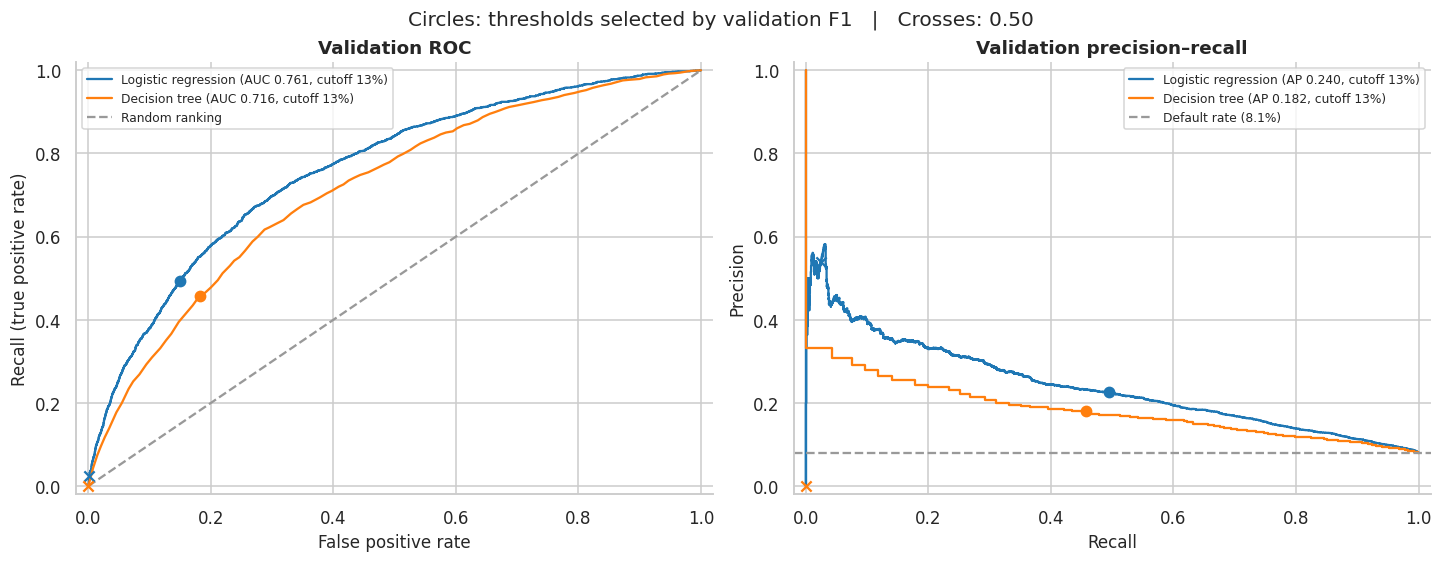

In [46]:
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_curve

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
curves = [
    ("Logistic regression", logreg_val_probabilities, logreg_threshold_sweep, logreg_threshold),
    ("Decision tree", tree_val_probabilities, tree_threshold_sweep, tree_threshold),
]

for (name, probabilities, sweep, threshold), color in zip(curves, ["tab:blue", "tab:orange"]):
    fpr, tpr, _ = roc_curve(y_val, probabilities, drop_intermediate=False)
    precision, recall, _ = precision_recall_curve(y_val, probabilities)
    auc = roc_auc_score(y_val, probabilities)
    ap = average_precision_score(y_val, probabilities)
    ax_roc.plot(fpr, tpr, color=color, label=f"{name} (AUC {auc:.3f}, cutoff {threshold:.0%})")
    ax_pr.step(recall, precision, where="post", color=color, label=f"{name} (AP {ap:.3f}, cutoff {threshold:.0%})")

    for cutoff, marker in [(PROBABILITY_THRESHOLD, "x"), (threshold, "o")]:
        point = sweep.loc[sweep["threshold"] == cutoff].iloc[0]
        ax_roc.scatter(point["false positive rate"], point["recall"], marker=marker, color=color, s=45, zorder=4)
        ax_pr.scatter(point["recall"], point["precision"], marker=marker, color=color, s=45, zorder=4)

ax_roc.plot([0, 1], [0, 1], linestyle="--", color="0.6", label="Random ranking")
ax_pr.axhline(y_val.mean(), linestyle="--", color="0.6", label=f"Default rate ({y_val.mean():.1%})")
ax_roc.set(title="Validation ROC", xlabel="False positive rate", ylabel="Recall (true positive rate)")
ax_pr.set(title="Validation precision–recall", xlabel="Recall", ylabel="Precision")
for axis in (ax_roc, ax_pr):
    axis.set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.02))
    axis.legend(loc="best", fontsize=8)
fig.suptitle("Circles: thresholds selected by validation F1   |   Crosses: 0.50")
plt.show()


### 6.6 Discussion and comparison with the other models

The tree provides decision paths that can be inspected for individual applicants. Logistic regression summarises associations through coefficients, while the SVM decision uses its support vectors. The comparison below uses ROC-AUC for ranking and reports the classification metrics at each model's stated cutoff. The reported fit times reflect different hardware. The SVM's final fit also includes probability calibration.

Kaggle scores the test applicants by ROC-AUC and reports a public score on one part of the test set and a private score on the rest. Table 6.5 adds these scores to the local results, and Table 6.6 shows their differences from the validation AUC. All three models score lower on Kaggle than on the validation rows, by 0.005 to 0.007 on the public part and 0.010 to 0.015 on the private part. The decision tree has the largest drop, consistent with its larger gap between training and validation AUC.


In [47]:
# Kaggle ROC-AUC scores for the three late submissions (see the screenshot below)
kaggle_scores = {
    "Logistic regression": {"public": 0.75570, "private": 0.75182},
    "SVM": {"public": 0.75759, "private": 0.75182},
    "Decision tree": {"public": 0.70869, "private": 0.70047},
}
model_results = {
    "Logistic regression": (logreg_metrics, logreg_fit_seconds, f"{logreg_threshold:.2f} probability"),
    "SVM": (svm_metrics, best_svm_fit_seconds, "0 decision score"),
    "Decision tree": (tree_metrics, tree_fit_seconds, f"{tree_threshold:.2f} probability"),
}

comparison_rows = []
summary_rows = []
for name, (metrics, fit_seconds, cutoff) in model_results.items():
    val_auc = metrics.loc["ROC-AUC", "validation"]
    public = kaggle_scores[name]["public"]
    private = kaggle_scores[name]["private"]
    for part in ("train", "validation"):
        row = {"model": name, "split": part, **metrics[part].to_dict()}
        row["Kaggle public"] = (public if public is not None else "Pending") if part == "validation" else "—"
        row["Kaggle private"] = (private if private is not None else "Pending") if part == "validation" else "—"
        comparison_rows.append(row)
    summary_rows.append({
        "model": name,
        "train − validation AUC": metrics.loc["ROC-AUC", "train"] - val_auc,
        "public − validation AUC": np.nan if public is None else public - val_auc,
        "private − validation AUC": np.nan if private is None else private - val_auc,
        "classification cutoff": cutoff,
        "final fit time (s)": fit_seconds,
    })

model_comparison = pd.DataFrame(comparison_rows)
model_summary = pd.DataFrame(summary_rows)
print("Table 6.5 · Training, validation and Kaggle results")
display(model_comparison.round(4))
print("Table 6.6 · Generalisation gaps and fit times")
display(model_summary.round(4).fillna("Pending"))

validation_results = model_comparison[model_comparison["split"] == "validation"]
best_validation_row = validation_results.loc[validation_results["ROC-AUC"].idxmax()]
print(f"Highest validation ROC-AUC: {best_validation_row['model']}, {best_validation_row['ROC-AUC']:.4f}.")


Table 6.5 · Training, validation and Kaggle results


,model,split,ROC-AUC,precision,recall,F1,accuracy,Kaggle public,Kaggle private
0,Logistic regression,train,0.7651,0.2233,0.4970,0.3082,0.8199,—,—
1,Logistic regression,validation,0.7613,0.2253,0.4941,0.3094,0.8220,0.7557,0.75182
2,SVM,train,0.7716,0.1722,0.7026,0.2766,0.7033,—,—
3,SVM,validation,0.7626,0.1719,0.7022,0.2762,0.7030,0.75759,0.75182
4,Decision tree,train,0.7461,0.1935,0.4909,0.2776,0.7937,—,—
5,Decision tree,validation,0.7158,0.1813,0.4574,0.2596,0.7894,0.70869,0.70047


Table 6.6 · Generalisation gaps and fit times


,model,train − validation AUC,public − validation AUC,private − validation AUC,classification cutoff,final fit time (s)
0,Logistic regression,0.0038,-0.0056,-0.0095,0.13 probability,4.9700
1,SVM,0.0090,-0.0050,-0.0108,0 decision score,18.9918
2,Decision tree,0.0303,-0.0071,-0.0153,0.13 probability,3.9476


Highest validation ROC-AUC: SVM, 0.7626.


**Kaggle submission evidence.** Figure 6.1 shows the three late submissions and their scores.

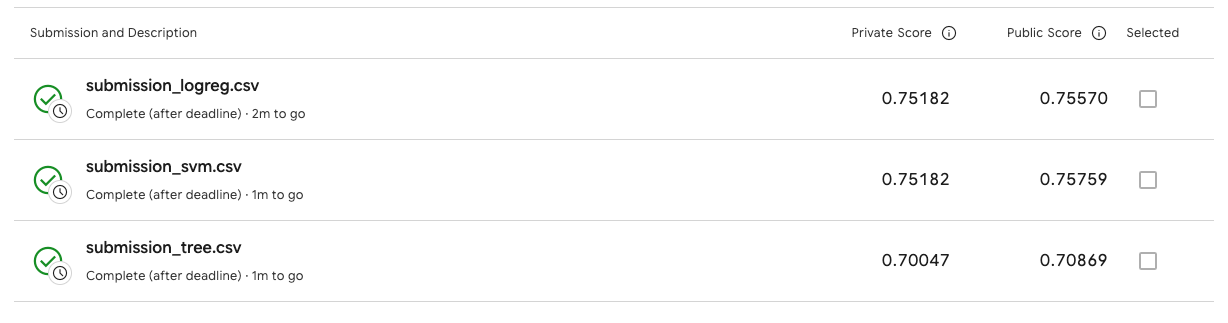

Figure 6.1 · Kaggle submissions (scored after the competition deadline)

| model | validation ROC-AUC | Kaggle public | Kaggle private |
|:--|--:|--:|--:|
| Logistic regression | 0.7613 | 0.7557 | 0.7518 |
| SVM | 0.7626 | 0.7576 | 0.7518 |
| Decision tree | 0.7158 | 0.7087 | 0.7005 |

The models rank the same way on validation and on Kaggle. The SVM and logistic regression are practically tied: the SVM leads by 0.0013 on validation and 0.0019 on the public part, and both reach 0.7518 on the private part. The decision tree is about 0.05 lower on every split. 

The main difference between the validation and Kaggle results is the size of the drop on unseen applicants. Logistic regression and the SVM lose 0.010 to 0.011 on the private part, while the tree loses 0.015, in line with its larger overfitting gap. The SVM's submitted probabilities are on an inflated scale because of the balanced class weights (mean 0.41, against a default rate of about 8%). This does not affect ROC-AUC, which depends only on the order of the applicants, but the SVM's probabilities should not be read as calibrated default risks.

## References

[1] Home Credit Group, "Home Credit Default Risk," Kaggle competition, 2018. [Online]. Available: https://www.kaggle.com/c/home-credit-default-risk

[2] COMP 6831 Applied Machine Learning, "Data Preparation and Preprocessing for Machine Learning and Imbalanced Data," lecture notebook.